# Air Quality Index (AQI) Category Prediction — Classification Track

**Goal.** Predict the `AQI_Bucket` of a city-day (six ordered classes: *Good → Satisfactory → Moderate → Poor → Very Poor → Severe*) from pollutant readings, city and date features.

**Data.** `city_day.csv` — daily air-quality records for 26 Indian cities (29,531 rows, 16 columns).

**Approach.**

| Step | What happens |
|---|---|
| A. EDA | Understand data quality, target balance, distributions and relationships |
| B. Preprocessing | Clean, engineer features, stratified train/test split, leakage-safe pipeline |
| D. Classification | Train 10 classifiers → compare → tune with GridSearchCV → compare again → pick a final model |
| H. Conclusion | Findings, limitations and next steps |

# A. Dataset Loading and Exploratory Data Analysis

## A1. Dataset Overview

In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

label_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

AQI_COLORS = {
    "Good": "#2E9E5B", "Satisfactory": "#9CCC4E", "Moderate": "#F2C744",
    "Poor": "#F08A3C", "Very Poor": "#D9453D", "Severe": "#8E1B3A",
}
METRIC_COLORS = {
    "Accuracy": "#264653", "Precision": "#2A9D8F",
    "Recall": "#E9C46A", "Weighted F1": "#E76F51",
}

In [116]:
def plot_metric_bars(df, name_col, title, figsize=(14, 6.5)):
    """Grouped bars for Accuracy / Precision / Recall / Weighted F1 (one group per model)."""
    metrics = list(METRIC_COLORS)
    x = np.arange(len(df))
    n = len(metrics)
    width = 0.8 / n

    fig, ax = plt.subplots(figsize=figsize)
    for i, metric in enumerate(metrics):
        pos = x + (i - (n - 1) / 2) * width
        ax.bar(pos, df[metric], width, label=metric,
               color=METRIC_COLORS[metric], edgecolor="white", linewidth=0.8)

    # Print the weighted-F1 value above its bar so the ranking can be read directly
    f1_pos = x + ((n - 1) / 2) * width
    for xi, value in zip(f1_pos, df["Weighted F1"]):
        ax.text(xi, value + 0.012, f"{value:.3f}", ha="center", va="bottom", fontsize=8.5)

    ax.set_xticks(x)
    ax.set_xticklabels(df[name_col], rotation=30, ha="right")
    ax.set_ylim(0, 1.18)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_ylabel("Score")
    ax.set_title(title, pad=14)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.grid(axis="x", visible=False)
    ax.legend(ncol=n, loc="upper center", frameon=False)
    plt.tight_layout()
    plt.show()


def plot_auc_bars(df, name_col, title):
    """Horizontal bars for weighted one-vs-rest ROC-AUC, best model highlighted."""
    d = df.sort_values("ROC-AUC")
    colors = ["#2A9D8F"] * (len(d) - 1) + ["#E76F51"]

    fig, ax = plt.subplots(figsize=(9, 5.2))
    ax.barh(d[name_col], d["ROC-AUC"], color=colors, edgecolor="white")
    for y, value in enumerate(d["ROC-AUC"]):
        ax.text(value + 0.004, y, f"{value:.4f}", va="center", fontsize=9.5)
    ax.set_xlim(0.5, 1.02)
    ax.set_xlabel("Weighted multiclass ROC-AUC (OvR)   |   0.5 = random guessing")
    ax.set_title(title)
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

In [117]:
from google.colab import drive
import os
drive.mount('/content/drive')
path="/content/drive/MyDrive/Colab Notebooks/city_day.csv"
df = pd.read_csv(path)

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [118]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [119]:
df.shape

(29531, 16)

In [120]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [121]:
df.columns

Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='object')

> **Observation:** The dataset has **29,531 daily records × 16 columns** covering **26 Indian cities**: 12 pollutant concentrations (PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene), the `AQI` value, the `AQI_Bucket` label, plus `City` and `Date`.
> `describe()` already shows strong right skew — e.g. PM2.5 has a mean of ≈67 but a median of ≈49 and a maximum of ≈950; PM10 has a mean of ≈118, a median of ≈96 and a maximum of 1,000.
> Every pollutant column has missing entries, and the target `AQI_Bucket` is missing for 4,681 rows. Because `AQI_Bucket` is derived directly from `AQI`, `AQI` cannot be used as a feature.

## A2. Missing Values

In [122]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing.sort_values("Missing Percentage", ascending=False)

,Missing Count,Missing Percentage
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


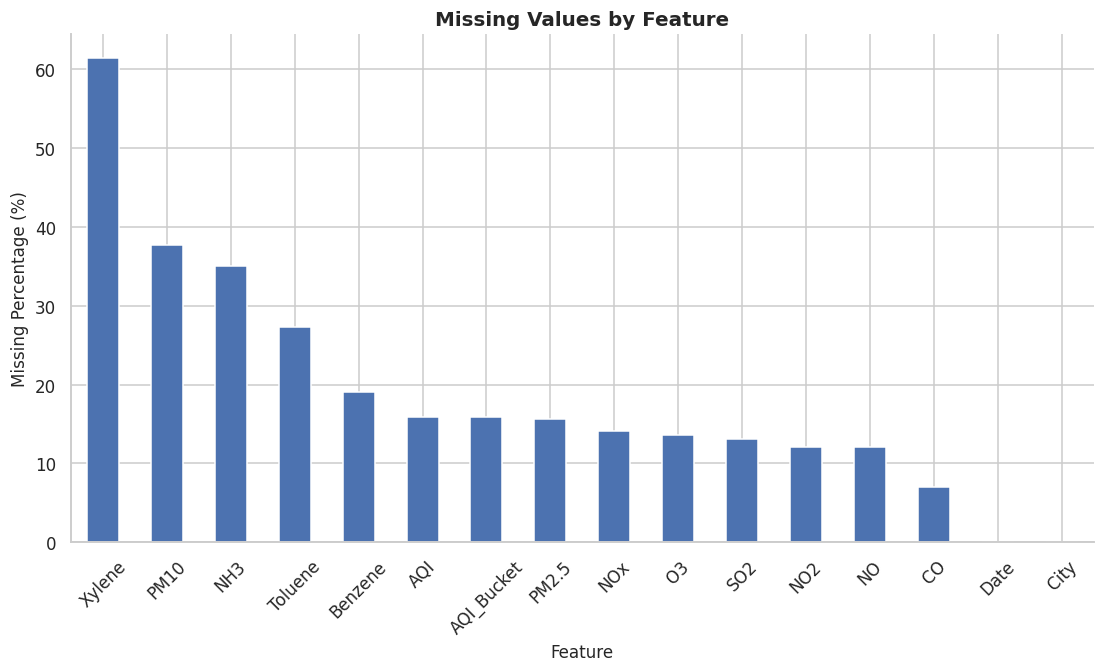

In [123]:
plt.figure(figsize=(12, 6))

missing["Missing Percentage"].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Missing Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45)

plt.show()

> **Observation:** Missingness is substantial. Xylene (61.3%), PM10 (37.7%), NH3 (35.0%) and Toluene (27.2%) are the worst; Benzene is at 19.0%, most other pollutants sit between 12% and 16%, and CO is the most complete pollutant (7.0%). `City` and `Date` are complete.
> Dropping every row with a missing feature would remove at least 61% of the data (all rows missing Xylene), so values are **imputed inside the modelling pipeline** (median, fitted on training data only). Features with heavy missingness (Xylene, PM10, NH3) will carry less reliable information after imputation.

## A3. Target and City Distribution

In [124]:
# Target class distribution
print("AQI_Bucket class distribution:")
print(df['AQI_Bucket'].value_counts())

print("\nRows with missing AQI_Bucket:", df['AQI_Bucket'].isnull().sum())
print("Total rows:", len(df))

AQI_Bucket class distribution:
AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

Rows with missing AQI_Bucket: 4681
Total rows: 29531


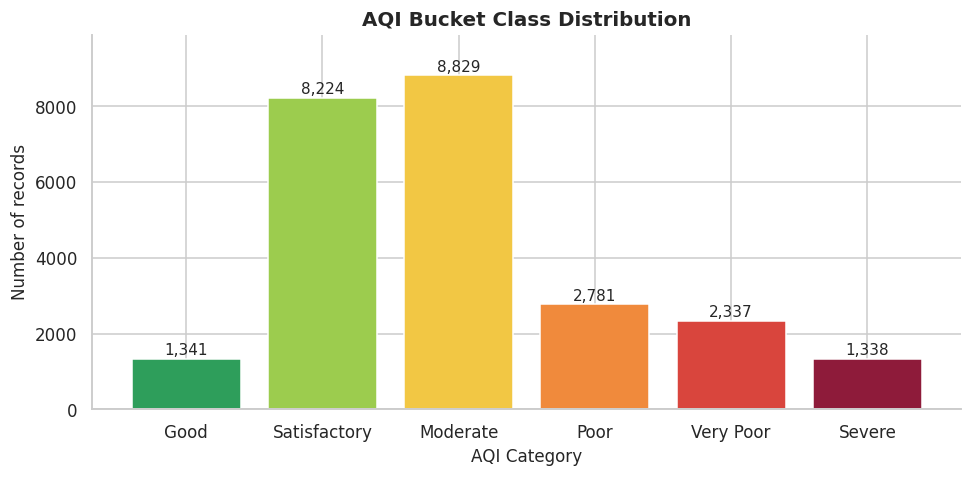

In [125]:
# Target class distribution
class_counts = df['AQI_Bucket'].value_counts().reindex(label_order)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(class_counts.index, class_counts.values,
              color=[AQI_COLORS[c] for c in class_counts.index], edgecolor="white")
for bar, value in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 100, f"{value:,}", ha="center", fontsize=10)
ax.set_title("AQI Bucket Class Distribution")
ax.set_xlabel("AQI Category")
ax.set_ylabel("Number of records")
ax.set_ylim(0, class_counts.max() * 1.12)
plt.tight_layout()
plt.show()

> **Observation:** The target is clearly **imbalanced**. Moderate (8,829 records, 35.5% of labelled rows) and Satisfactory (8,224, 33.1%) together make up ≈69% of the data, followed by Poor (11.2%) and Very Poor (9.4%). Good (1,341) and Severe (1,338) are the rarest at ≈5.4% each — a 6.6 : 1 ratio between the largest and smallest class.
> Accuracy alone can therefore hide poor performance on the rare classes, so **weighted F1 and per-class confusion matrices** are used alongside accuracy throughout this notebook.

In [126]:
print(df['City'].value_counts())

City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Mumbai                2009
Lucknow               2009
Delhi                 2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Kochi                  162
Ernakulam              162
Aizawl                 113
Name: count, dtype: int64


> **Observation:** Six cities (Ahmedabad, Bengaluru, Chennai, Delhi, Lucknow, Mumbai) have complete 2,009-day records, while some cities have far fewer (Aizawl 113, Kochi and Ernakulam 162 each). City coverage is therefore uneven and larger cities contribute more training data. Since pollution levels differ by location, `City` is kept as a (one-hot encoded) feature.

## A4. Feature Distributions and Relationships

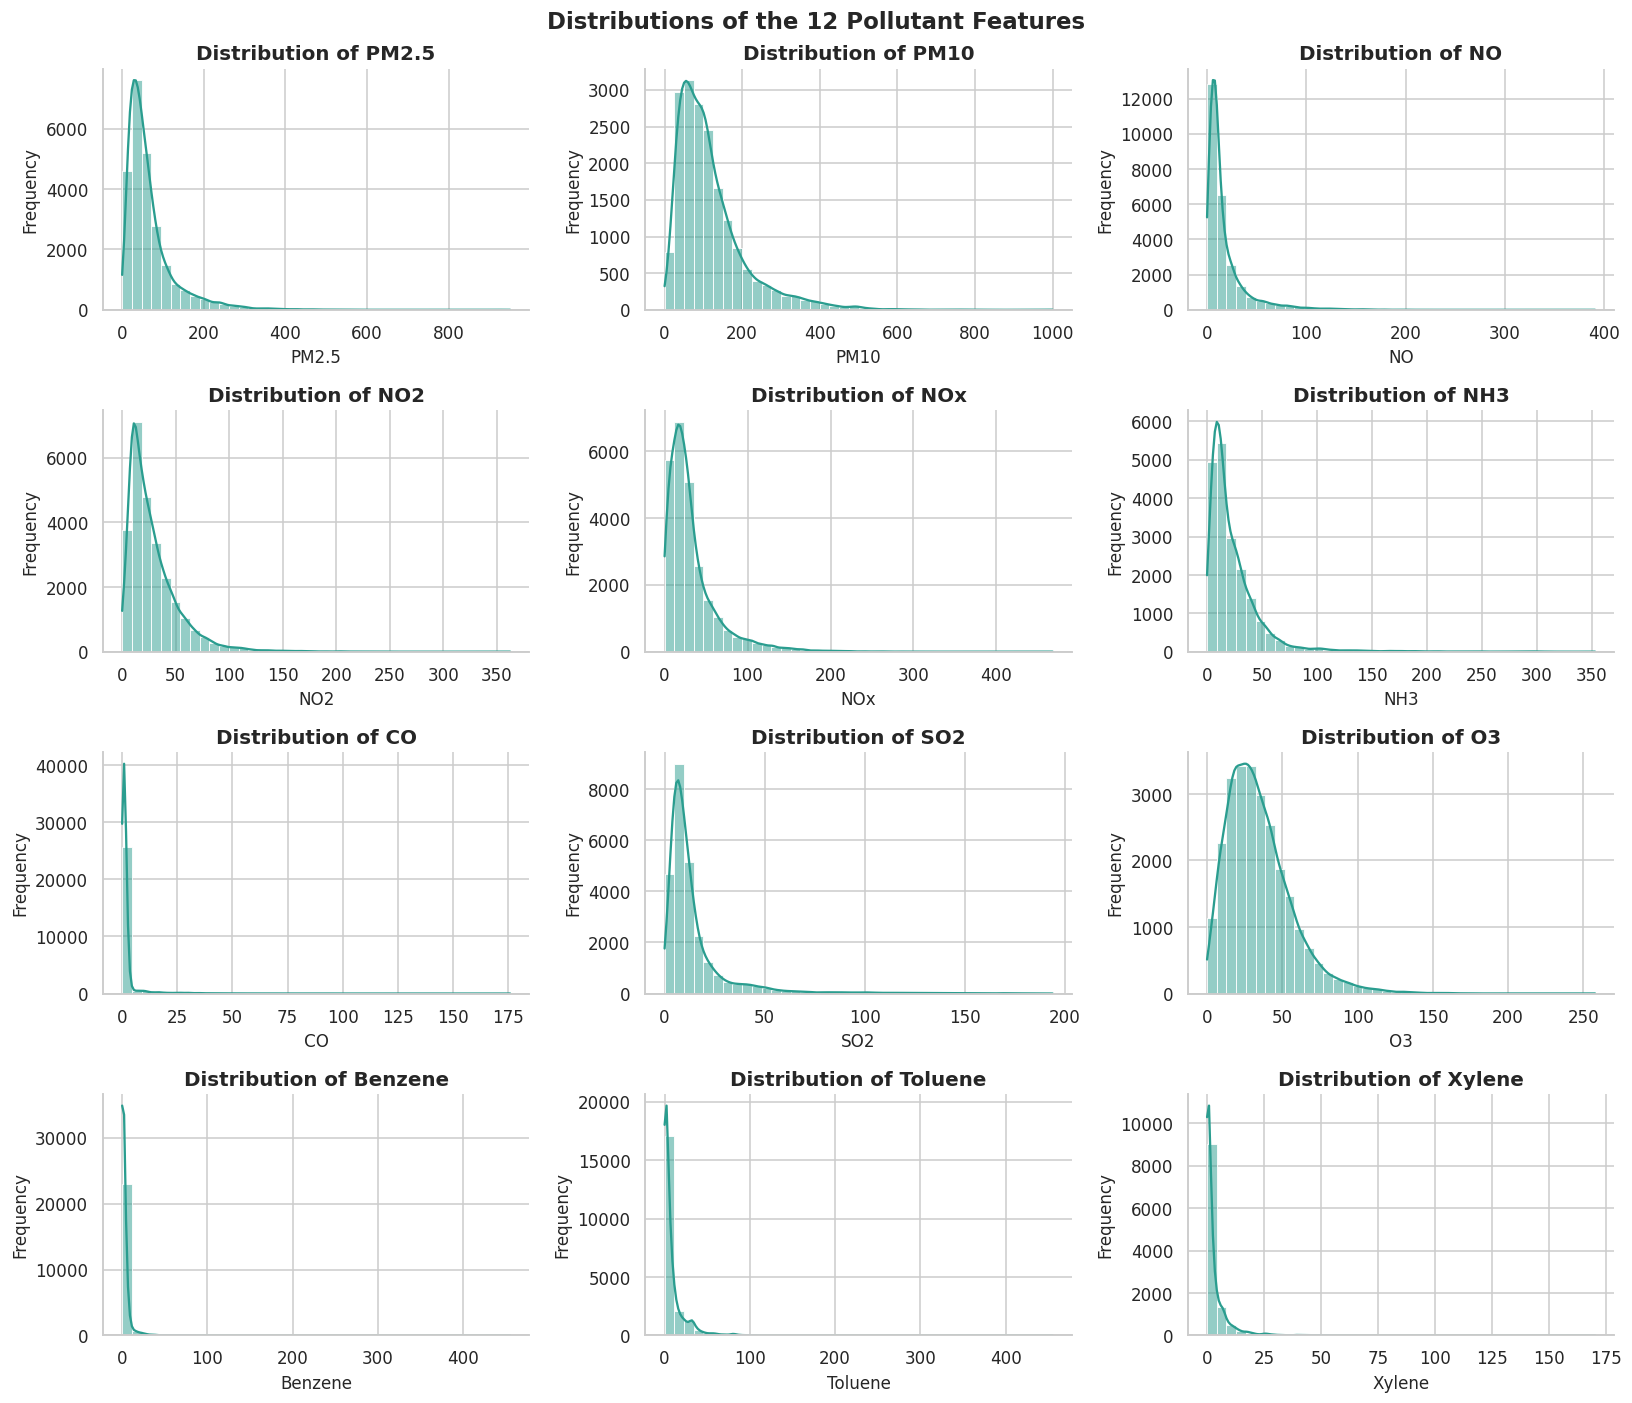

In [75]:
eda_columns = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx',
    'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene'
]

fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for ax, col in zip(axes.flat, eda_columns):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color="#2A9D8F")
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
fig.suptitle("Distributions of the 12 Pollutant Features", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

> **Observation:** All twelve pollutants are strongly **right-skewed**: most readings are low, while a small number of extreme days stretch the tail. PM2.5 and PM10 have the widest ranges (maximum ≈950 and 1,000 against medians of ≈49 and ≈96). This points to using a scaling method that is not distorted by extreme values (RobustScaler) and to keeping, rather than deleting, the high-pollution days.

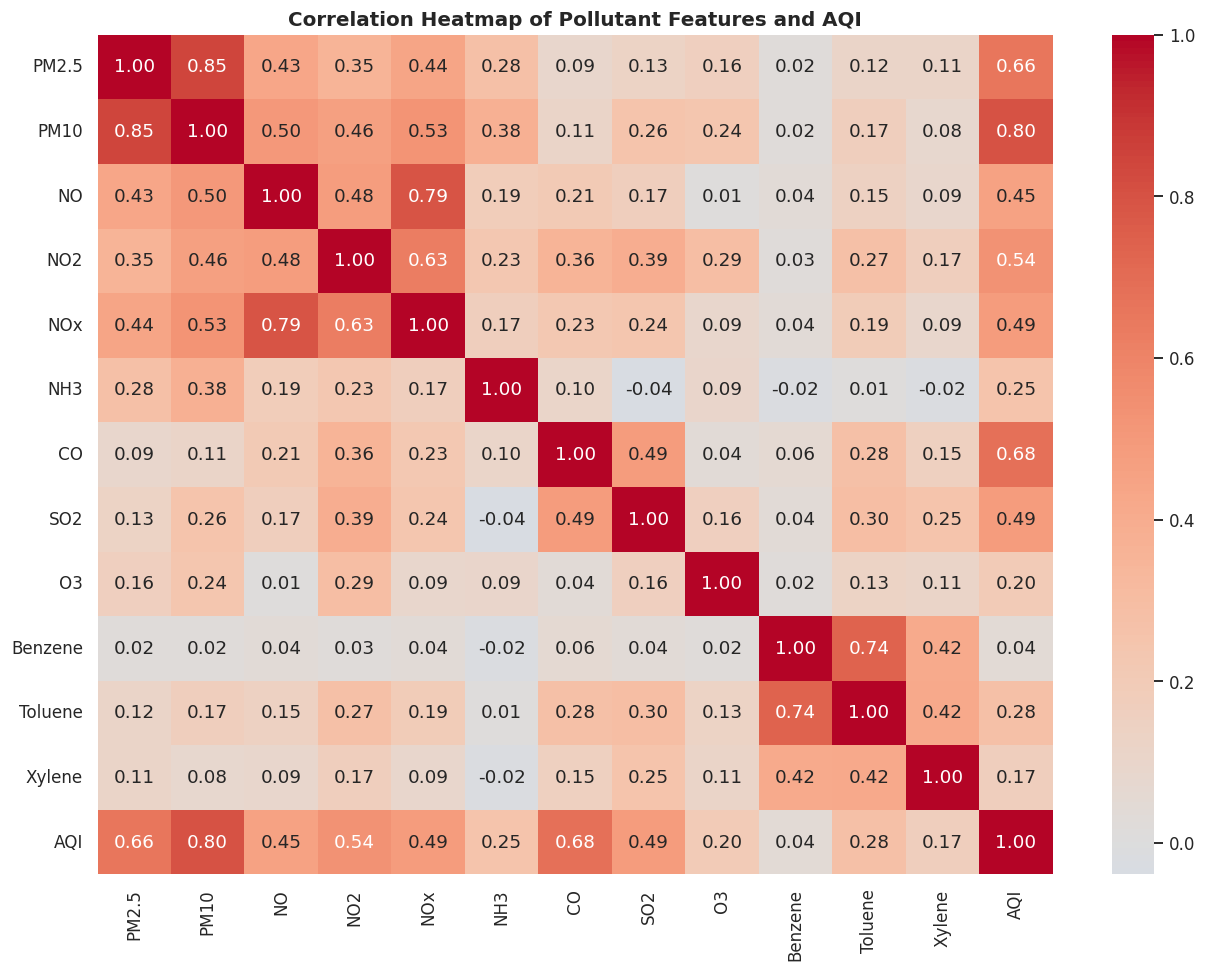

In [76]:
# Correlation heatmap
correlation_columns = eda_columns + ['AQI']

plt.figure(figsize=(12, 9))
sns.heatmap(
    df[correlation_columns].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)
plt.title('Correlation Heatmap of Pollutant Features and AQI')
plt.tight_layout()
plt.show()

> **Observation:** Several pollutants are strongly inter-correlated: PM2.5–PM10 (0.85), NO–NOx (0.79) and Benzene–Toluene (0.74). This redundancy matters most for Naive Bayes and linear models; tree ensembles are less affected.
> `AQI` correlates most strongly with **PM10 (0.80), CO (0.68) and PM2.5 (0.66)**, followed by NO2 (0.54), while Benzene (0.04), Xylene (0.17) and O3 (0.20) are only weakly related. Particulate matter and CO should therefore be the most informative predictors.

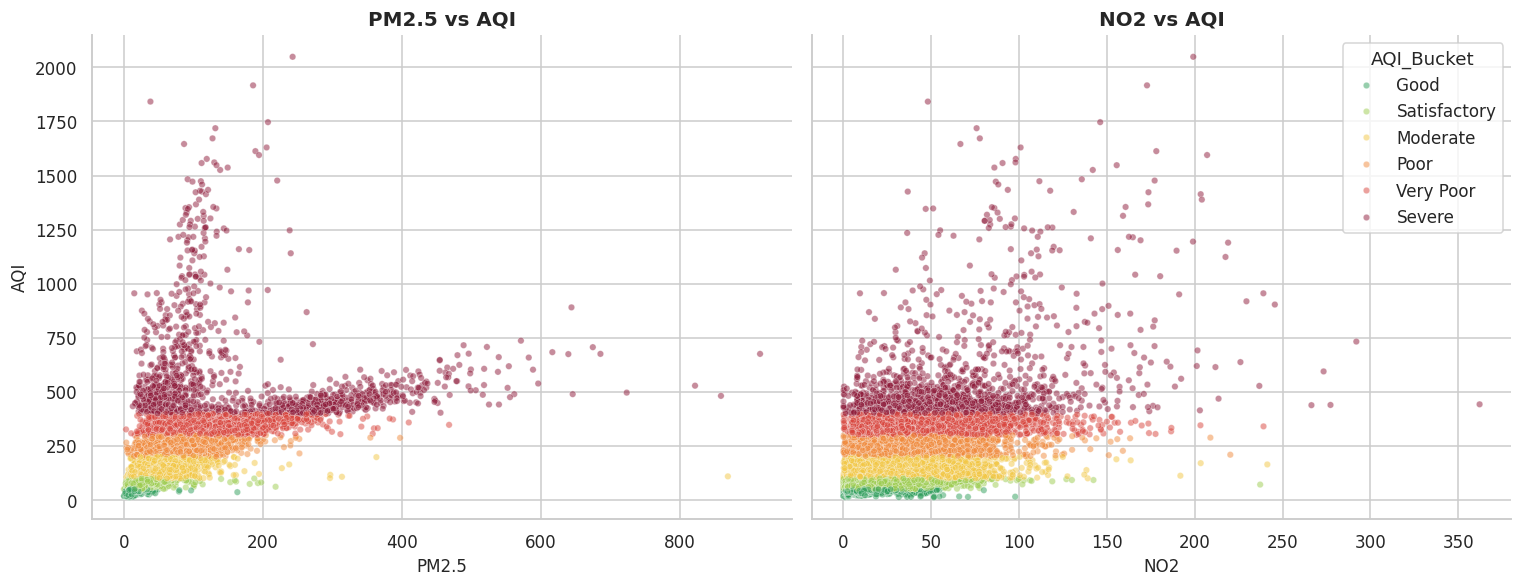

In [77]:
# Feature vs AQI, coloured by AQI category
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

sns.scatterplot(data=df, x='PM2.5', y='AQI', hue='AQI_Bucket', hue_order=label_order,
                palette=AQI_COLORS, alpha=0.5, s=18, ax=axes[0], legend=False)
axes[0].set_title('PM2.5 vs AQI')

sns.scatterplot(data=df, x='NO2', y='AQI', hue='AQI_Bucket', hue_order=label_order,
                palette=AQI_COLORS, alpha=0.5, s=18, ax=axes[1])
axes[1].set_title('NO2 vs AQI')
axes[1].legend(title='AQI_Bucket', loc='upper right')

plt.tight_layout()
plt.show()

> **Observation:** AQI generally rises with PM2.5, but the relationship is not one-to-one: many **Severe** records (AQI up to ≈2,000) occur at only ≈50–200 µg/m³ of PM2.5, which suggests that on those days AQI is being driven by another pollutant (such as PM10 or CO, which correlate more strongly with AQI).
> NO2 shows only a weak association — every category spans a similar NO2 range, so NO2 alone cannot separate the classes.
> **Takeaway:** no single pollutant is sufficient; a model has to combine several features.

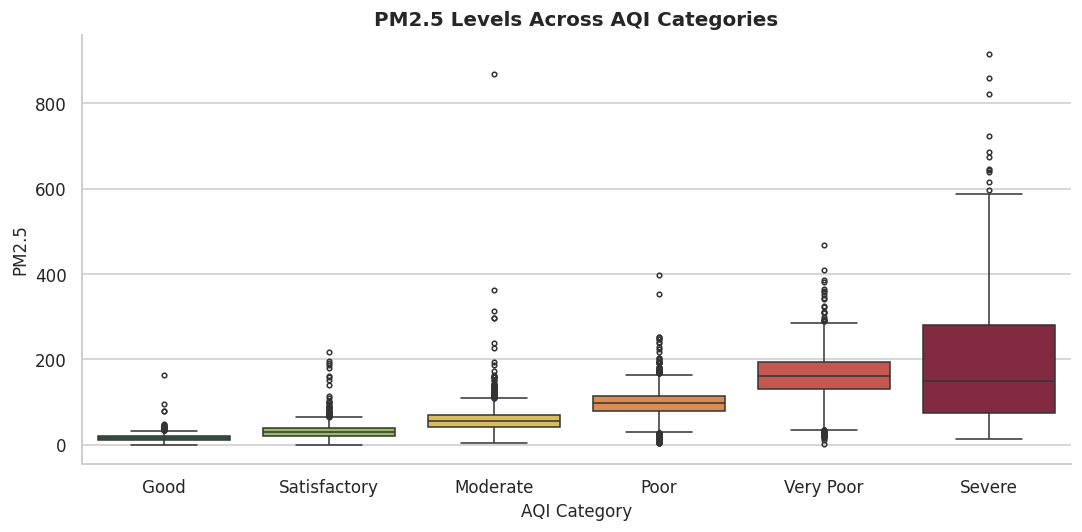

In [78]:
# PM2.5 per AQI class
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='AQI_Bucket', y='PM2.5', order=label_order,
            hue='AQI_Bucket', palette=AQI_COLORS, legend=False, fliersize=3)
plt.title('PM2.5 Levels Across AQI Categories')
plt.xlabel('AQI Category')
plt.tight_layout()
plt.show()

> **Observation:** The median PM2.5 rises steadily from Good (a few µg/m³) through Satisfactory, Moderate and Poor up to Very Poor (≈160). **Severe does not have a higher median than Very Poor** (≈150), but it has by far the widest spread (box roughly 75–280), so it overlaps heavily with Very Poor and even Poor. Outliers appear in every category.
> PM2.5 separates the lower categories well but cannot reliably separate Very Poor from Severe — this foreshadows the Very Poor ↔ Severe confusions seen later in the confusion matrices.

# B. Preprocessing and Feature Engineering

## B1. Data Cleaning

In [79]:
# Check for outliers using IQR method
Q1 = df[eda_columns].quantile(0.25)
Q3 = df[eda_columns].quantile(0.75)
IQR = Q3 - Q1

outlier_counts = (
    (df[eda_columns] < (Q1 - 1.5 * IQR)) |
    (df[eda_columns] > (Q3 + 1.5 * IQR))
).sum()

print("Number of outliers in each feature:")
print(outlier_counts)

Number of outliers in each feature:
PM2.5      1982
PM10       1057
NO         2459
NO2        1188
NOx        1868
NH3        1015
CO         2475
SO2        2578
O3          713
Benzene    1668
Toluene    2427
Xylene     1119
dtype: int64


> **Observation:** The IQR rule flags between 713 (O3) and 2,578 (SO2) values per pollutant — roughly 3–10% of the non-missing readings. These extreme values most likely reflect genuine pollution episodes rather than data-entry errors, so they are **kept**. RobustScaler (median/IQR based) is used later to limit their influence.

In [80]:
# check for duplicate rows
print(df.duplicated().sum())

0


> **Observation:** No duplicate rows were found, so no records were removed.

In [81]:
# check for physically impossible negetive values
print("Negative PM2.5:", (df['PM2.5'] < 0).sum())
print("Negative PM10:", (df['PM10'] < 0).sum())
print("Negative NO2:", (df['NO2'] < 0).sum())
print("Negative CO:", (df['CO'] < 0).sum())
print("Negative O3:", (df['O3'] < 0).sum())

Negative PM2.5: 0
Negative PM10: 0
Negative NO2: 0
Negative CO: 0
Negative O3: 0


> **Observation:** None of the five pollutants checked contains negative values, so the readings are physically valid and need no correction.

In [82]:
# Remove rows where the target is missing
df_cleaned = df.dropna(subset=['AQI_Bucket']).copy()

# AQI is excluded from the ML features to prevent data leakage
df_cleaned = df_cleaned.drop(columns=['AQI'])

print("Rows after removing missing target:", len(df_cleaned))
print("Remaining missing values will be handled inside the preprocessing pipeline after the train/test split.")

Rows after removing missing target: 24850
Remaining missing values will be handled inside the preprocessing pipeline after the train/test split.


> **Observation:** 4,681 rows (15.9%) had no `AQI_Bucket` and were removed, leaving **24,850 labelled rows**. `AQI` was dropped because the bucket is a direct function of it — keeping it would let the models read the answer (**target leakage**) instead of learning from pollutant levels.

In [83]:
df_cleaned["Date"] = pd.to_datetime(df_cleaned["Date"], errors="coerce")

df_cleaned["Year"] = df_cleaned["Date"].dt.year
df_cleaned["Month"] = df_cleaned["Date"].dt.month
df_cleaned["Day"] = df_cleaned["Date"].dt.day
df_cleaned["DayOfWeek"] = df_cleaned["Date"].dt.dayofweek

df_cleaned = df_cleaned.drop(columns=["Date"])

print("Date features created: Year, Month, Day, and DayOfWeek.")

Date features created: Year, Month, Day, and DayOfWeek.


> **Observation:** `Year`, `Month`, `Day` and `DayOfWeek` let the models pick up long-term trends and seasonal patterns (for example winter pollution episodes) without using the raw date string.

In [84]:
# AQI_Bucket stays as readable class labels (ordered Good -> Severe, defined in the setup cell).
# City is encoded in the preprocessing pipeline; target encoding is not required.

print("Target classes:", label_order)
print("City will be handled using OneHotEncoder.")

Target classes: ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
City will be handled using OneHotEncoder.


## B2. Feature Engineering

In [85]:
# Engineered Feature 1: NO to NO2 ratio — captures combustion type
df_cleaned['NO_NO2_ratio'] = df_cleaned['NO'] / (df_cleaned['NO2'] + 1)

# Engineered Feature 2: Weighted combined particulate matter
df_cleaned['PM_combined'] = (
    df_cleaned['PM2.5'] * 0.6 + df_cleaned['PM10'] * 0.4
)

# Engineered Feature 3: Total VOC load
df_cleaned['VOC_total'] = (
    df_cleaned['Benzene'] + df_cleaned['Toluene'] + df_cleaned['Xylene']
)

print("Engineered features created:")
print(df_cleaned[['NO_NO2_ratio', 'PM_combined', 'VOC_total']].head())

Engineered features created:
    NO_NO2_ratio  PM_combined  VOC_total
28      0.233255          NaN       3.16
29      0.466644          NaN       4.85
30      0.724599          NaN       7.92
31      1.009285          NaN      26.31
32      1.502616          NaN      36.13


### Feature engineering justification

- **NO_NO2_ratio:** the relative contribution of NO and NO2, which may capture pollution characteristics (e.g. combustion type) that the individual concentrations do not show on their own.
- **PM_combined:** combines PM2.5 and PM10 into a single particulate-matter indicator (weights 0.6 / 0.4).
- **VOC_total:** combines Benzene, Toluene and Xylene into an overall VOC indicator.

> **Observation:** The first rows show `PM_combined` as NaN wherever PM10 is missing. Because these features are computed from raw columns that contain missing values, each one is missing whenever **any** of its components is missing (VOC_total depends on Xylene, which is 61% missing), and those gaps are then median-imputed in the pipeline. They are therefore noisier than the raw features. (If desired, `sum(min_count=1)` would keep partial information.)

## B3. Train/Test Split

In [86]:
# Separate features and target. AQI is deliberately excluded to avoid target leakage.
feature_cols = [
    "City", "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene",
    "Year", "Month", "Day", "DayOfWeek",
    "NO_NO2_ratio", "PM_combined", "VOC_total"
]

X = df_cleaned[feature_cols].copy()
y = df_cleaned["AQI_Bucket"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Features:", X.shape)
print("Target:", y.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Features: (24850, 20)
Target: (24850,)
Training set: (19880, 20)
Test set: (4970, 20)


> **Observation:** An 80/20 **stratified** split gives 19,880 training and 4,970 test rows. Stratification keeps every class at the same proportion in both sets, which matters because Good and Severe are only ≈5% of the data (268 test records each).

## B4. Preprocessing Pipeline

In [87]:
# Numerical and categorical feature groups
numeric_features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene", "Year", "Month", "Day", "DayOfWeek",
    "NO_NO2_ratio", "PM_combined", "VOC_total"
]
categorical_features = ["City"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline ready.")
print("Numeric features: median imputation + RobustScaler")
print("City: most-frequent imputation + OneHotEncoder")
print("Preprocessing is fitted within each model pipeline on training data only.")


Preprocessing pipeline ready.
Numeric features: median imputation + RobustScaler
City: most-frequent imputation + OneHotEncoder
Preprocessing is fitted within each model pipeline on training data only.


> **Observation:** All preprocessing lives inside the model pipelines, so imputation medians, scaling parameters and one-hot categories are learned from **training data only** — and re-fitted inside every cross-validation fold during tuning. This prevents information from the test set leaking into the models. RobustScaler uses the median and IQR, which suits the skewed, outlier-heavy pollutant data.

# D. Classification Track

Ten classifiers are trained on the same stratified split and the same preprocessing pipeline: five classical models (Part A) and five ensemble/neural-network models (Part B). They are then compared, tuned with 3-fold stratified GridSearchCV (selection metric: weighted F1) and compared again. The held-out test set is only used for final evaluation.

## D1. Evaluation Setup

In [88]:
all_results = {}
fitted_models = {}
model_predictions = {}
model_scores = {}

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, show_cm=False):
    """Fit a model, calculate required metrics, save results, and show its confusion matrix."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_te, y_pred, average="weighted", zero_division=0)
    weighted_f1 = f1_score(y_te, y_pred, average="weighted", zero_division=0)

    # All required classifiers use probability estimates for multiclass OvR ROC-AUC.
    roc_auc = np.nan
    y_score = None
    try:
        y_score = model.predict_proba(X_te)
        classifier = model.named_steps["classifier"]
        class_labels = classifier.classes_
        roc_auc = roc_auc_score(
            y_te,
            y_score,
            labels=class_labels,
            multi_class="ovr",
            average="weighted"
        )
    except (ValueError, AttributeError, TypeError) as error:
        print(f"ROC-AUC could not be calculated for {name}: {error}")

    all_results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "Weighted F1": weighted_f1,
        "ROC-AUC": roc_auc
    }
    fitted_models[name] = model
    model_predictions[name] = y_pred
    model_scores[name] = y_score

    print(f"\n{name} — Test Set Evaluation")
    print(f"Accuracy       : {acc:.4f}")
    print(f"Weighted Precision: {prec:.4f}")
    print(f"Weighted Recall   : {rec:.4f}")
    print(f"Weighted F1-score : {weighted_f1:.4f}")
    print(f"Multiclass OvR ROC-AUC: {roc_auc:.4f}" if not np.isnan(roc_auc)
          else "Multiclass OvR ROC-AUC: unavailable")

    if show_cm:
        fig, ax = plt.subplots(figsize=(8, 6))
        ConfusionMatrixDisplay.from_predictions(
            y_te,
            y_pred,
            labels=label_order,
            display_labels=label_order,
            cmap="Blues",
            xticks_rotation=45,
            values_format="d",
            ax=ax,
            colorbar=False
        )
        ax.set_title(f"Confusion Matrix — {name}")
        plt.tight_layout()
        plt.show()

    return model

print("Evaluation function ready. All baseline confusion matrices will be shown together in the dedicated evaluation cell.")

Evaluation function ready. All baseline confusion matrices will be shown together in the dedicated evaluation cell.


> **Note:** Reported metrics are accuracy, weighted precision, weighted recall, weighted F1 and weighted one-vs-rest ROC-AUC. Weighted averaging accounts for class imbalance. Weighted recall is mathematically identical to accuracy, so those two numbers will always match.

## D2. Part A — Classical Classifiers

### 1. Logistic Regression

In [89]:
from sklearn.linear_model import LogisticRegression

# Increased max_iter to 3000 to ensure convergence during tuning
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

lr_model = evaluate_model(
    'Logistic Regression',
    lr_model,
    X_train, X_test,
    y_train, y_test
)

print("\nLogistic Regression trained successfully!")


Logistic Regression — Test Set Evaluation
Accuracy       : 0.7813
Weighted Precision: 0.7795
Weighted Recall   : 0.7813
Weighted F1-score : 0.7774
Multiclass OvR ROC-AUC: 0.9462

Logistic Regression trained successfully!


### 2. K-Nearest Neighbors

In [90]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=7))
])

knn_model = evaluate_model(
    'K-Nearest Neighbors',
    knn_model,
    X_train, X_test,
    y_train, y_test
)

print("\nK-Nearest Neighbors trained successfully!")


K-Nearest Neighbors — Test Set Evaluation
Accuracy       : 0.7557
Weighted Precision: 0.7522
Weighted Recall   : 0.7557
Weighted F1-score : 0.7519
Multiclass OvR ROC-AUC: 0.9255

K-Nearest Neighbors trained successfully!


### 3. Naive Bayes

In [91]:
from sklearn.naive_bayes import GaussianNB

nb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

nb_model = evaluate_model(
    'Naive Bayes',
    nb_model,
    X_train, X_test,
    y_train, y_test
)

print("\nNaive Bayes trained successfully!")


Naive Bayes — Test Set Evaluation
Accuracy       : 0.2111
Weighted Precision: 0.5569
Weighted Recall   : 0.2111
Weighted F1-score : 0.1938
Multiclass OvR ROC-AUC: 0.7351

Naive Bayes trained successfully!


### 4. Decision Tree Classifier

In [92]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=10, random_state=42))
])

dt_model = evaluate_model(
    'Decision Tree',
    dt_model,
    X_train, X_test,
    y_train, y_test
)

print("\nDecision Tree Classifier trained successfully!")


Decision Tree — Test Set Evaluation
Accuracy       : 0.7855
Weighted Precision: 0.7848
Weighted Recall   : 0.7855
Weighted F1-score : 0.7839
Multiclass OvR ROC-AUC: 0.9201

Decision Tree Classifier trained successfully!


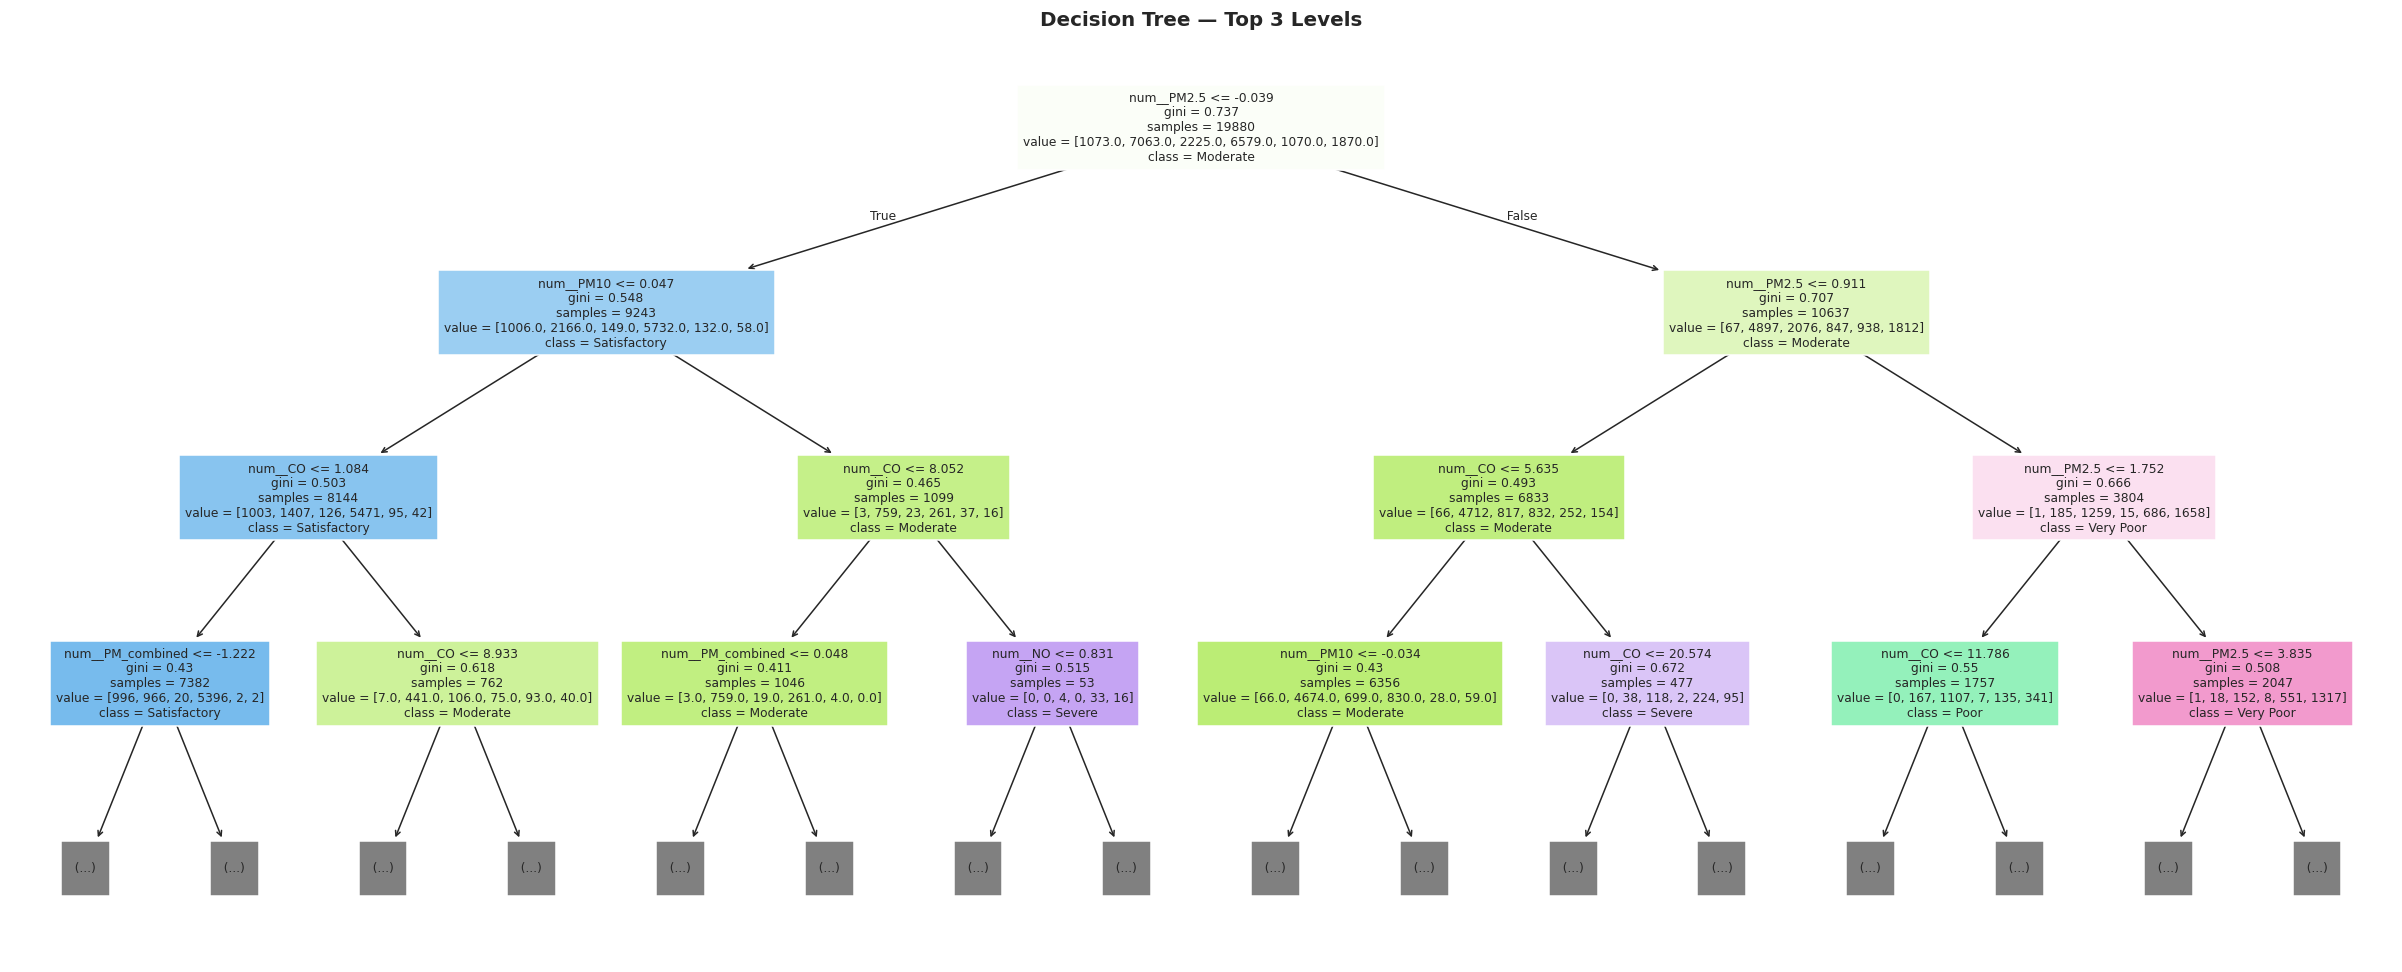

In [93]:
from sklearn.tree import plot_tree

# Visualise the top 3 levels of the decision tree
preprocessor_fitted = dt_model.named_steps['preprocessor']
tree_fitted = dt_model.named_steps['classifier']

feature_names = preprocessor_fitted.get_feature_names_out()

plt.figure(figsize=(22, 9))
plot_tree(
    tree_fitted,
    max_depth=3,
    feature_names=feature_names,
    class_names=tree_fitted.classes_,
    filled=True,
    fontsize=8
)
plt.title("Decision Tree — Top 3 Levels")
plt.tight_layout()
plt.show()

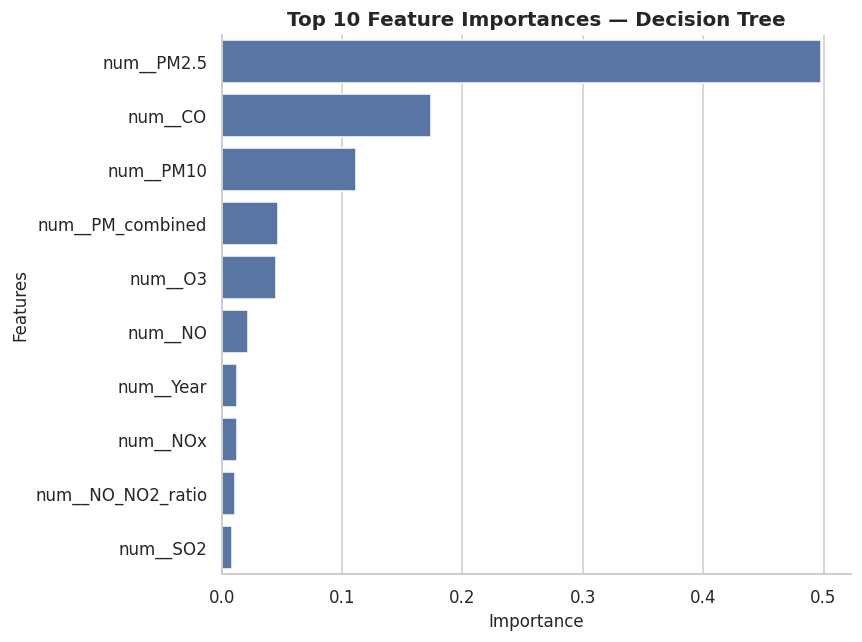

In [94]:
# Feature Importance from the Decision Tree

# Get the fitted preprocessing and Decision Tree
fitted_preprocessor = dt_model.named_steps['preprocessor']
tree_model = dt_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Calculate and sort feature importances
importances = pd.Series(
    tree_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

# Plot the top 10 features
plt.figure(figsize=(8, 6))

sns.barplot(
    x=importances.values,
    y=importances.index
)

plt.title('Top 10 Feature Importances — Decision Tree')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

> **Observation:** **PM2.5 dominates** (importance ≈ 0.50), followed by CO (≈ 0.17) and PM10 (≈ 0.11); these three account for ≈ 78% of the importance. The engineered `PM_combined` ranks 4th (≈ 0.05) and `NO_NO2_ratio` 9th, while `VOC_total` and the `City` columns do not reach the top 10 — the pollutant readings carry most of the signal. These are impurity-based importances from a single tree, and correlated features (PM2.5, PM10, PM_combined) share credit, so they are indicative rather than exact.

### 5. Support Vector Machine

In [95]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(C=1.0, kernel='rbf', probability=True, random_state=42))
])

svm_model = evaluate_model(
    'SVM',
    svm_model,
    X_train, X_test,
    y_train, y_test
)

print("\nSVM trained successfully!")


SVM — Test Set Evaluation
Accuracy       : 0.7545
Weighted Precision: 0.7629
Weighted Recall   : 0.7545
Weighted F1-score : 0.7341
Multiclass OvR ROC-AUC: 0.9414

SVM trained successfully!


### Part A — Summary Table and Chart

In [96]:
# Part-A comparison table
part_a_result_names = [
    "Logistic Regression", "K-Nearest Neighbors", "Naive Bayes",
    "Decision Tree", "SVM"
]
part_a_df = (
    pd.DataFrame.from_dict(
        {name: all_results[name] for name in part_a_result_names},
        orient="index"
    )
    .rename_axis("Model")
    .reset_index()
    .sort_values("Weighted F1", ascending=False)
    .reset_index(drop=True)
)
display(part_a_df.round(4))

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Decision Tree,0.7855,0.7848,0.7855,0.7839,0.9201
1,Logistic Regression,0.7813,0.7795,0.7813,0.7774,0.9462
2,K-Nearest Neighbors,0.7557,0.7522,0.7557,0.7519,0.9255
3,SVM,0.7545,0.7629,0.7545,0.7341,0.9414
4,Naive Bayes,0.2111,0.5569,0.2111,0.1938,0.7351


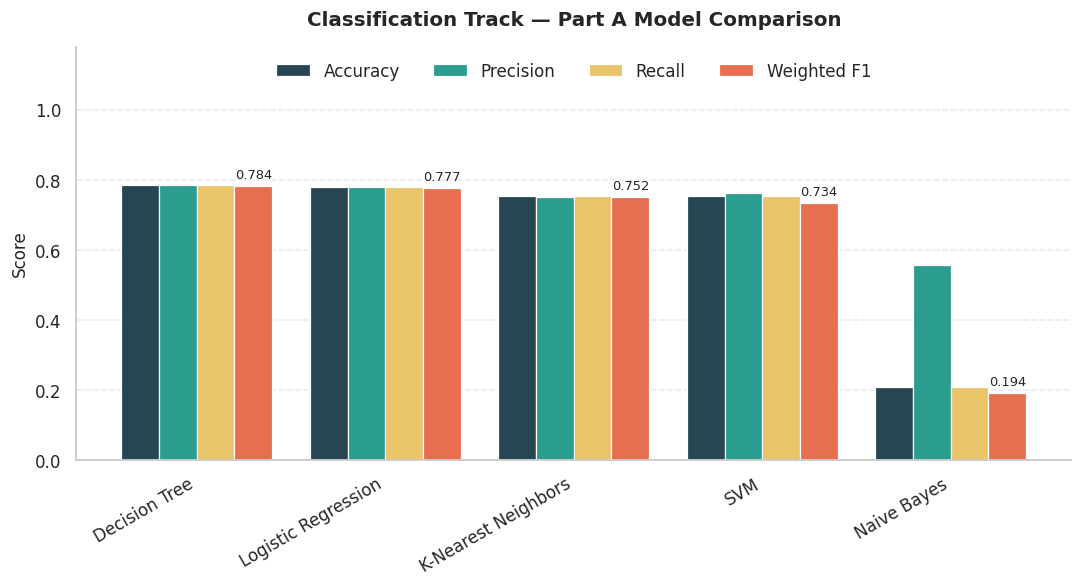

In [97]:
# Part A — grouped bar chart of the four threshold-based metrics
plot_metric_bars(part_a_df, "Model", "Classification Track — Part A Model Comparison", figsize=(10, 5.5))

> **Observation:** Within Part A the **Decision Tree and Logistic Regression lead** (weighted F1 0.7839 and 0.7774), KNN and SVM follow (0.7519 and 0.7341), and **Naive Bayes is far behind** (0.1938). Precision is higher than recall for SVM and Naive Bayes, meaning they are right when they predict a class but miss many true cases of it. ROC-AUC (table above) ranks Logistic Regression (0.9462) and SVM (0.9414) higher than their F1 suggests, because AUC measures how well probabilities rank the classes rather than the final class decision.

## D3. Part B — Ensemble and Neural Network Classifiers

Each model below is trained and evaluated separately, using the same stratified train/test split and preprocessing pipeline.

### 6. Random Forest

In [98]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model = evaluate_model(
    "Random Forest", rf_model,
    X_train, X_test, y_train, y_test
)
part_b_fitted_models = {"Random Forest": rf_model}


Random Forest — Test Set Evaluation
Accuracy       : 0.8103
Weighted Precision: 0.8093
Weighted Recall   : 0.8103
Weighted F1-score : 0.8085
Multiclass OvR ROC-AUC: 0.9617


### 7. AdaBoost

In [99]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ))
])

ada_model = evaluate_model(
    "AdaBoost", ada_model,
    X_train, X_test, y_train, y_test
)
part_b_fitted_models["AdaBoost"] = ada_model


AdaBoost — Test Set Evaluation
Accuracy       : 0.6875
Weighted Precision: 0.6582
Weighted Recall   : 0.6875
Weighted F1-score : 0.6630
Multiclass OvR ROC-AUC: 0.8976


### 8. Gradient Boosting

In [100]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

gb_model = evaluate_model(
    "Gradient Boosting", gb_model,
    X_train, X_test, y_train, y_test
)
part_b_fitted_models["Gradient Boosting"] = gb_model


Gradient Boosting — Test Set Evaluation
Accuracy       : 0.8093
Weighted Precision: 0.8078
Weighted Recall   : 0.8093
Weighted F1-score : 0.8080
Multiclass OvR ROC-AUC: 0.9603


### 9. Bagging

In [101]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=50,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

bagging_model = evaluate_model(
    "Bagging", bagging_model,
    X_train, X_test, y_train, y_test
)
part_b_fitted_models["Bagging"] = bagging_model


Bagging — Test Set Evaluation
Accuracy       : 0.8099
Weighted Precision: 0.8089
Weighted Recall   : 0.8099
Weighted F1-score : 0.8090
Multiclass OvR ROC-AUC: 0.9567


### 10. MLP Classifier

In [102]:
from sklearn.neural_network import MLPClassifier

# Keep AQI_Bucket as the original string labels so all models share the same target format.
mlp_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=300,
        early_stopping=False,
        random_state=RANDOM_STATE
    ))
])

mlp_model = evaluate_model(
    "MLP Classifier", mlp_model,
    X_train, X_test, y_train, y_test
)
part_b_fitted_models["MLP Classifier"] = mlp_model


MLP Classifier — Test Set Evaluation
Accuracy       : 0.7901
Weighted Precision: 0.7885
Weighted Recall   : 0.7901
Weighted F1-score : 0.7886
Multiclass OvR ROC-AUC: 0.9557


## D4. Baseline Comparison — All 10 Models

Consolidated test-set results for the ten baseline classifiers (default / hand-picked hyperparameters), sorted by weighted F1.

In [103]:
# One consolidated test-set comparison for all ten baseline algorithms
all_results_df = (
    pd.DataFrame.from_dict(all_results, orient="index")
    .rename_axis("Algorithm")
    .reset_index()
    .sort_values("Weighted F1", ascending=False)
    .reset_index(drop=True)
)
display(all_results_df.round(4))

,Algorithm,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Bagging,0.8099,0.8089,0.8099,0.8090,0.9567
1,Random Forest,0.8103,0.8093,0.8103,0.8085,0.9617
2,Gradient Boosting,0.8093,0.8078,0.8093,0.8080,0.9603
3,MLP Classifier,0.7901,0.7885,0.7901,0.7886,0.9557
4,Decision Tree,0.7855,0.7848,0.7855,0.7839,0.9201
5,Logistic Regression,0.7813,0.7795,0.7813,0.7774,0.9462
6,K-Nearest Neighbors,0.7557,0.7522,0.7557,0.7519,0.9255
7,SVM,0.7545,0.7629,0.7545,0.7341,0.9414
8,AdaBoost,0.6875,0.6582,0.6875,0.6630,0.8976
9,Naive Bayes,0.2111,0.5569,0.2111,0.1938,0.7351


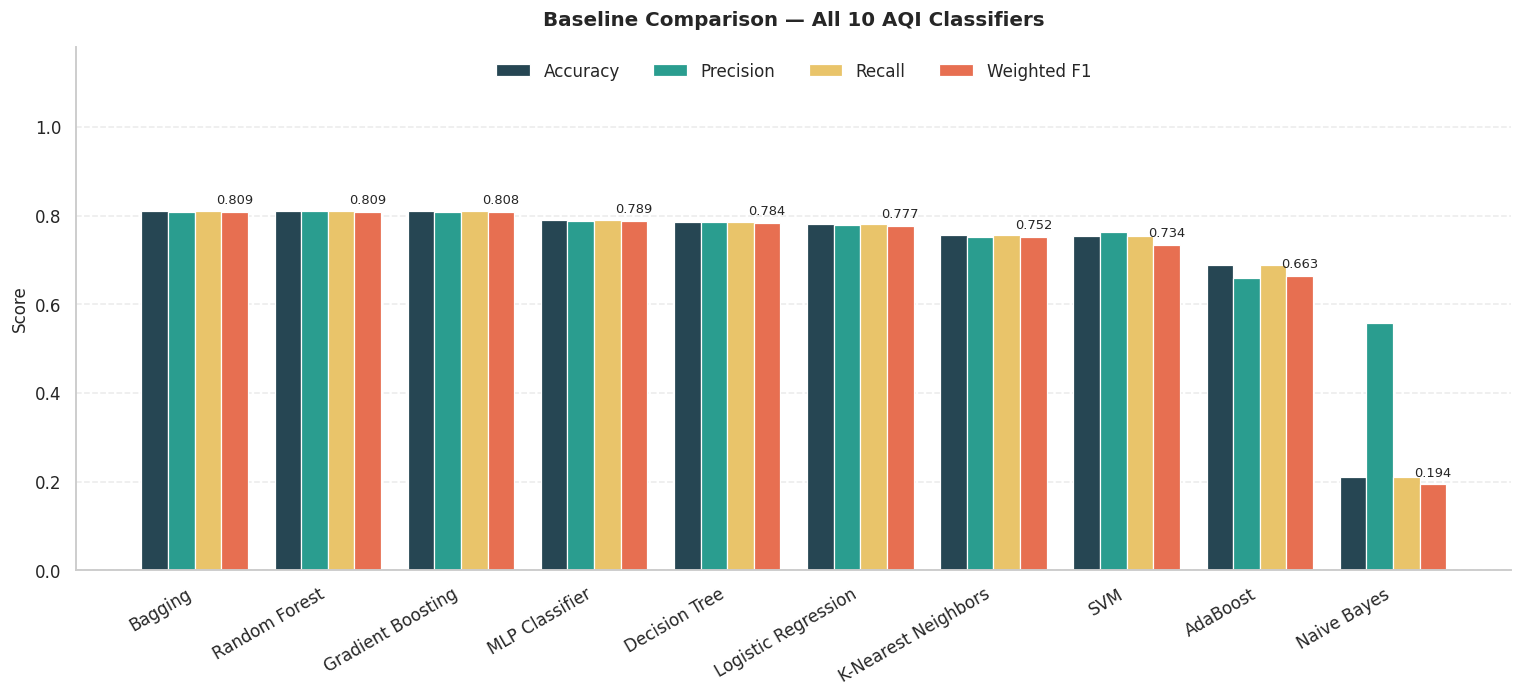

In [104]:
plot_metric_bars(all_results_df, "Algorithm", "Baseline Comparison — All 10 AQI Classifiers")

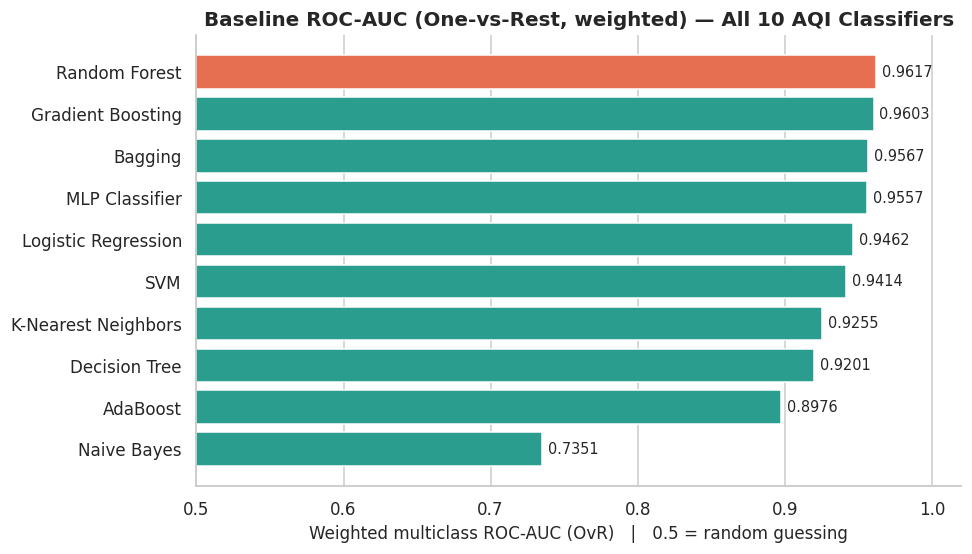

In [105]:
plot_auc_bars(all_results_df, "Algorithm", "Baseline ROC-AUC (One-vs-Rest, weighted) — All 10 AQI Classifiers")

> **Observation:**
> - **Tree ensembles lead:** Bagging (weighted F1 0.8090), Random Forest (0.8085) and Gradient Boosting (0.8080) are within 0.001 of each other — far less than the sampling error of the test set — so they are effectively tied. Random Forest has the best accuracy (0.8103) and ROC-AUC (0.9617).
> - **Simple models are not far behind:** MLP 0.7886, Decision Tree 0.7839 and Logistic Regression 0.7774. A single depth-limited tree is only ≈0.025 F1 below the best model.
> - **KNN (0.7519) and SVM (0.7341) trail**; SVM is held back by almost never predicting the Good class.
> - **AdaBoost (0.6630) is the weakest ensemble and Naive Bayes collapses** (F1 0.1938).
> - Accuracy and recall bars are identical by definition (weighted recall = accuracy). In the ROC-AUC chart, Logistic Regression (0.9462) and SVM (0.9414) rank above where their F1 would put them, while Naive Bayes is lowest (0.7351).

### Confusion Matrices — Baseline Models

Each confusion matrix uses the same held-out test set and the six AQI_Bucket labels in a consistent order. Rows are actual categories and columns are predicted categories.

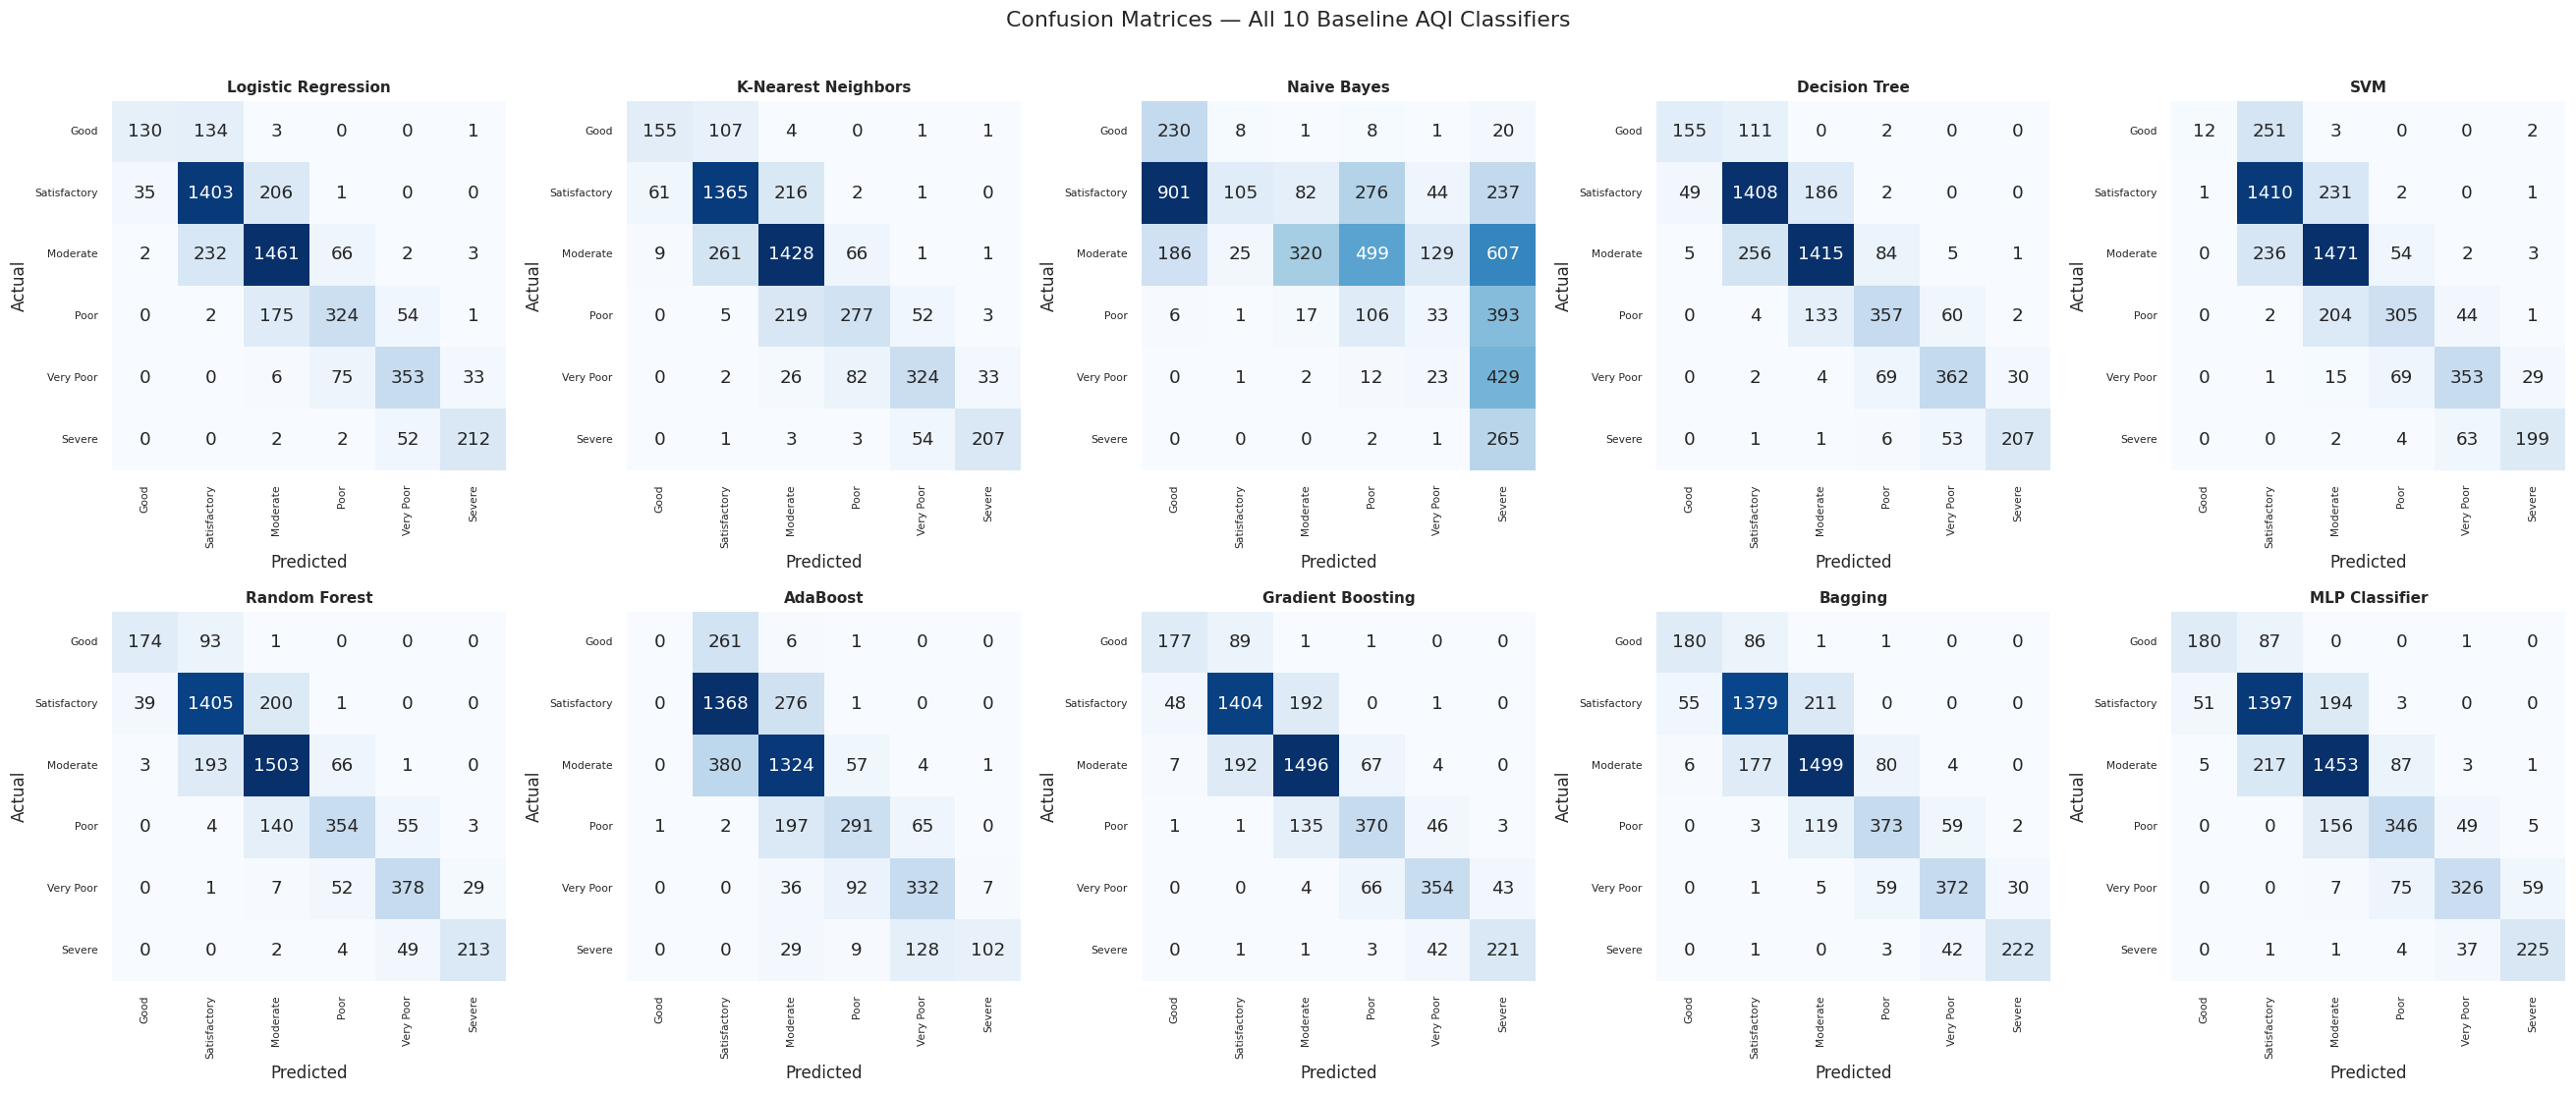

In [106]:
# Display all ten baseline confusion matrices in a 2 x 5 layout
fig, axes = plt.subplots(2, 5, figsize=(24, 10))
labels = label_order
all_model_names = list(model_predictions.keys())

for ax, name in zip(axes.flat, all_model_names):
    y_pred = model_predictions[name]
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=labels, yticklabels=labels, ax=ax
    )
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)

plt.suptitle("Confusion Matrices — All 10 Baseline AQI Classifiers", y=1.01)
plt.tight_layout()
plt.show()

> **Observation:**
> - **Errors are almost always between neighbouring categories** (Good ↔ Satisfactory, Satisfactory ↔ Moderate, Moderate ↔ Poor, Poor ↔ Very Poor, Very Poor ↔ Severe). That is natural because the buckets are consecutive slices of one continuous AQI scale; confusions between distant categories are rare for every model except Naive Bayes.
> - **Good is the hardest class** (268 test records). Correctly identified: Logistic Regression 130, KNN and Decision Tree 155, Random Forest 174, Gradient Boosting 177, Bagging and MLP 180, SVM only 12, AdaBoost 0.
> - **Naive Bayes** labels most Satisfactory days as Good (901 of 1,645) and most Poor / Very Poor days as Severe (393 of 556 and 429 of 467) — the source of its collapse.
> - The two biggest classes, Satisfactory and Moderate, are predicted well (≈1,400–1,500 correct each by the top models) but exchange roughly 200 records in each direction.

## D5. Hyperparameter Tuning

One dictionary of parameter grids and one loop tune all ten classifiers. Each grid is applied to the corresponding pipeline, so preprocessing is re-fitted inside every cross-validation fold, and the held-out test set is never used to select hyperparameters. Three-fold stratified cross-validation keeps the search practical on this dataset; **weighted F1** is the selection metric.

In [107]:
# Collect the ten models that were actually trained in this notebook
all_model_names = [
    "Logistic Regression", "K-Nearest Neighbors", "Naive Bayes",
    "Decision Tree", "SVM", "Random Forest", "AdaBoost",
    "Gradient Boosting", "Bagging", "MLP Classifier"
]

classification_models = {name: fitted_models[name] for name in all_model_names}
print("Models included:", len(classification_models))
print(list(classification_models.keys()))

Models included: 10
['Logistic Regression', 'K-Nearest Neighbors', 'Naive Bayes', 'Decision Tree', 'SVM', 'Random Forest', 'AdaBoost', 'Gradient Boosting', 'Bagging', 'MLP Classifier']


In [108]:
# Use the pipeline step name "classifier" for all model-specific parameters.
parameter_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1.0, 10.0]
    },
    "K-Nearest Neighbors": {
        "classifier__n_neighbors": [5, 7, 11],
        "classifier__weights": ["uniform", "distance"]
    },
    "Naive Bayes": {
        "classifier__var_smoothing": [1e-9, 1e-8, 1e-7]
    },
    "Decision Tree": {
        "classifier__max_depth": [6, 10, None],
        "classifier__min_samples_leaf": [1, 3]
    },
    "SVM": {
        "classifier__C": [0.5, 1.0, 2.0]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 15]
    },
    "AdaBoost": {
        "classifier__n_estimators": [50, 100],
        "classifier__learning_rate": [0.1, 0.5, 1.0]
    },
    "Gradient Boosting": {
        "classifier__n_estimators": [75, 100],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3]
    },
    "Bagging": {
        "classifier__n_estimators": [30, 50]
    },
    "MLP Classifier": {
        "classifier__hidden_layer_sizes": [(64,), (100,)],
        "classifier__alpha": [0.0001, 0.001]
    }
}

cv_tuning = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
tuned_models = {}
tuning_rows = []

for name in all_model_names:
    print(f"Tuning {name}...")
    search = GridSearchCV(
        estimator=clone(classification_models[name]),
        param_grid=parameter_grids[name],
        scoring="f1_weighted",
        cv=cv_tuning,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuning_rows.append({
        "Algorithm": name,
        "Best Parameters": search.best_params_,
        "Best CV Weighted F1": search.best_score_
    })

tuning_results_df = pd.DataFrame(tuning_rows).sort_values(
    "Best CV Weighted F1", ascending=False
).reset_index(drop=True)
display(tuning_results_df.round(4))

Tuning Logistic Regression...
Tuning K-Nearest Neighbors...
Tuning Naive Bayes...
Tuning Decision Tree...
Tuning SVM...
Tuning Random Forest...
Tuning AdaBoost...
Tuning Gradient Boosting...
Tuning Bagging...
Tuning MLP Classifier...


,Algorithm,Best Parameters,Best CV Weighted F1
0,Random Forest,"{'classifier__max_depth': 15, 'classifier__n_estimators': 200}",0.8011
1,Gradient Boosting,"{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}",0.8006
2,Bagging,{'classifier__n_estimators': 50},0.7988
3,MLP Classifier,"{'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (100,)}",0.7878
4,Logistic Regression,{'classifier__C': 10.0},0.7721
5,Decision Tree,"{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1}",0.7678
6,K-Nearest Neighbors,"{'classifier__n_neighbors': 11, 'classifier__weights': 'distance'}",0.7308
7,SVM,{'classifier__C': 2.0},0.7302
8,AdaBoost,"{'classifier__learning_rate': 1.0, 'classifier__n_estimators': 100}",0.6556
9,Naive Bayes,{'classifier__var_smoothing': 1e-07},0.3151


In [109]:
# Readable view of the best parameters found for each model
pd.set_option("display.max_colwidth", None)
tuning_view = tuning_results_df.copy()
tuning_view["Best Parameters"] = tuning_view["Best Parameters"].apply(
    lambda params: ", ".join(f"{k.replace('classifier__', '')}={v}" for k, v in params.items())
)
display(tuning_view.round(4))

,Algorithm,Best Parameters,Best CV Weighted F1
0,Random Forest,"max_depth=15, n_estimators=200",0.8011
1,Gradient Boosting,"learning_rate=0.1, max_depth=3, n_estimators=100",0.8006
2,Bagging,n_estimators=50,0.7988
3,MLP Classifier,"alpha=0.0001, hidden_layer_sizes=(100,)",0.7878
4,Logistic Regression,C=10.0,0.7721
5,Decision Tree,"max_depth=10, min_samples_leaf=1",0.7678
6,K-Nearest Neighbors,"n_neighbors=11, weights=distance",0.7308
7,SVM,C=2.0,0.7302
8,AdaBoost,"learning_rate=1.0, n_estimators=100",0.6556
9,Naive Bayes,var_smoothing=1e-07,0.3151


> **Observation:**
> - Cross-validated weighted F1 ranks **Random Forest (0.8011)**, Gradient Boosting (0.8006) and Bagging (0.7988) on top — the same trio as on the test set; the gap between the first two is only 0.0005.
> - CV scores are lower than the test scores (e.g. Random Forest 0.8011 in CV vs 0.8109 on the test set). Each CV fold trains on only two-thirds of the training data, whereas the final model is refitted on all of it, which likely explains the difference.
> - **Several best values sit at the edge of their grid** — Logistic Regression C = 10, KNN n_neighbors = 11, SVM C = 2.0, AdaBoost learning_rate = 1.0 and Naive Bayes var_smoothing = 1e-07 are all the largest value tried. Wider grids might improve those models further. Naive Bayes stays very low even after tuning (CV F1 0.3151), so its weakness is not a smoothing issue.

## D6. Baseline vs Tuned — All 10 Models

Each tuned model is evaluated once on the held-out test set and compared with its baseline counterpart using the same metrics. The first table shows every metric; the second is a compact view of the change in weighted F1 and ROC-AUC (green = improvement, red = decline).

In [110]:
# Evaluate every tuned model on the held-out test set and compare with baseline

tuned_predictions = {}
tuned_result_rows = []

for name in all_model_names:
    model = tuned_models[name]
    pred = model.predict(X_test)
    tuned_predictions[name] = pred

    prob = model.predict_proba(X_test)
    class_order = model.named_steps["classifier"].classes_
    tuned_auc = roc_auc_score(
        y_test, prob, labels=class_order,
        multi_class="ovr", average="weighted"
    )

    tuned_result_rows.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_test, pred, average="weighted", zero_division=0),
        "ROC-AUC": tuned_auc
    })

tuned_results_df = pd.DataFrame(tuned_result_rows)
comparison_rows = []
metric_names = ["Accuracy", "Precision", "Recall", "Weighted F1", "ROC-AUC"]
for name in all_model_names:
    base = all_results[name]
    tuned = tuned_results_df.loc[tuned_results_df["Algorithm"] == name].iloc[0]
    row = {"Algorithm": name}
    for metric in metric_names:
        row[f"Baseline {metric}"] = base[metric]
        row[f"Tuned {metric}"] = tuned[metric]
        row[f"Change in {metric}"] = tuned[metric] - base[metric]
    comparison_rows.append(row)

baseline_vs_tuned_df = pd.DataFrame(comparison_rows)
display(baseline_vs_tuned_df.round(4))

,Algorithm,Baseline Accuracy,Tuned Accuracy,Change in Accuracy,Baseline Precision,Tuned Precision,Change in Precision,Baseline Recall,Tuned Recall,Change in Recall,Baseline Weighted F1,Tuned Weighted F1,Change in Weighted F1,Baseline ROC-AUC,Tuned ROC-AUC,Change in ROC-AUC
0,Logistic Regression,0.7813,0.7821,0.0008,0.7795,0.7798,0.0003,0.7813,0.7821,0.0008,0.7774,0.7787,0.0013,0.9462,0.9467,0.0005
1,K-Nearest Neighbors,0.7557,0.7555,-0.0002,0.7522,0.7522,0.0000,0.7557,0.7555,-0.0002,0.7519,0.7514,-0.0005,0.9255,0.9341,0.0087
2,Naive Bayes,0.2111,0.3165,0.1054,0.5569,0.5497,-0.0072,0.2111,0.3165,0.1054,0.1938,0.3280,0.1342,0.7351,0.7795,0.0444
3,Decision Tree,0.7855,0.7855,0.0000,0.7848,0.7848,0.0000,0.7855,0.7855,0.0000,0.7839,0.7839,0.0000,0.9201,0.9201,0.0000
4,SVM,0.7545,0.7682,0.0137,0.7629,0.7752,0.0123,0.7545,0.7682,0.0137,0.7341,0.7533,0.0192,0.9414,0.9449,0.0035
5,Random Forest,0.8103,0.8107,0.0004,0.8093,0.8112,0.0020,0.8103,0.8107,0.0004,0.8085,0.8109,0.0023,0.9617,0.9604,-0.0014
6,AdaBoost,0.6875,0.6849,-0.0026,0.6582,0.6544,-0.0037,0.6875,0.6849,-0.0026,0.6630,0.6631,0.0001,0.8976,0.8785,-0.0191
7,Gradient Boosting,0.8093,0.8093,0.0000,0.8078,0.8078,0.0000,0.8093,0.8093,0.0000,0.8080,0.8080,0.0000,0.9603,0.9603,0.0000
8,Bagging,0.8099,0.8099,0.0000,0.8089,0.8089,0.0000,0.8099,0.8099,0.0000,0.8090,0.8090,0.0000,0.9567,0.9567,0.0000
9,MLP Classifier,0.7901,0.7901,0.0000,0.7885,0.7885,0.0000,0.7901,0.7901,0.0000,0.7886,0.7886,0.0000,0.9557,0.9557,0.0000


In [111]:
# Compact view of the impact of tuning
impact_df = baseline_vs_tuned_df[[
    "Algorithm",
    "Baseline Weighted F1", "Tuned Weighted F1", "Change in Weighted F1",
    "Baseline ROC-AUC", "Tuned ROC-AUC", "Change in ROC-AUC"
]]
change_cols = ["Change in Weighted F1", "Change in ROC-AUC"]

display(
    impact_df.style
    .format({c: "{:.4f}" for c in impact_df.columns if c != "Algorithm"})
    .format({c: "{:+.4f}" for c in change_cols})
    .background_gradient(subset=change_cols, cmap="RdYlGn", vmin=-0.02, vmax=0.02)
    .hide(axis="index")
)

Algorithm,Baseline Weighted F1,Tuned Weighted F1,Change in Weighted F1,Baseline ROC-AUC,Tuned ROC-AUC,Change in ROC-AUC
Logistic Regression,0.777425,0.778729,+0.0013,0.946226,0.946692,+0.0005
K-Nearest Neighbors,0.751920,0.751411,-0.0005,0.925486,0.934142,+0.0087
Naive Bayes,0.193794,0.327975,+0.1342,0.735096,0.779514,+0.0444
Decision Tree,0.783937,0.783937,+0.0000,0.920113,0.920113,+0.0000
SVM,0.734056,0.753296,+0.0192,0.941415,0.944902,+0.0035
Random Forest,0.808525,0.810858,+0.0023,0.961733,0.960372,-0.0014
AdaBoost,0.663018,0.663072,+0.0001,0.897581,0.878529,-0.0191
Gradient Boosting,0.807981,0.807981,+0.0000,0.960281,0.960281,+0.0000
Bagging,0.809038,0.809038,+0.0000,0.956749,0.956749,+0.0000
MLP Classifier,0.788644,0.788644,+0.0000,0.955666,0.955666,+0.0000


> **Observation:**
> - **Tuning helped very little for the strong models.** Gradient Boosting, Bagging, MLP and Decision Tree are unchanged — the best configuration in the grid was their baseline setting — while Random Forest and Logistic Regression each gain only +0.0023 weighted F1.
> - **The largest gains come from weak baselines:** Naive Bayes +0.1342 F1 (0.1938 → 0.3280, still unusable) and SVM +0.0192 (0.7341 → 0.7533), mainly because the tuned SVM recovers more Good days (12 → 36).
> - **A few small declines:** KNN F1 −0.0005; AdaBoost ROC-AUC −0.0191 although its F1 is flat (+0.0001); Random Forest ROC-AUC −0.0014. Tuning optimises weighted F1, so AUC can move the other way.
> - Differences should be read against the sampling error: with 4,970 test records the standard error of an accuracy near 0.81 is ≈ 0.006, so changes below ≈ 0.01 are within noise.

## D7. Tuned Models — Test-Set Performance

Test-set metrics of the tuned models only (sorted by weighted F1). A separate baseline-vs-tuned bar chart is not repeated here: the table above already gives the exact change for every metric.

,Algorithm,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Random Forest,0.8107,0.8112,0.8107,0.8109,0.9604
1,Bagging,0.8099,0.8089,0.8099,0.8090,0.9567
2,Gradient Boosting,0.8093,0.8078,0.8093,0.8080,0.9603
3,MLP Classifier,0.7901,0.7885,0.7901,0.7886,0.9557
4,Decision Tree,0.7855,0.7848,0.7855,0.7839,0.9201
5,Logistic Regression,0.7821,0.7798,0.7821,0.7787,0.9467
6,SVM,0.7682,0.7752,0.7682,0.7533,0.9449
7,K-Nearest Neighbors,0.7555,0.7522,0.7555,0.7514,0.9341
8,AdaBoost,0.6849,0.6544,0.6849,0.6631,0.8785
9,Naive Bayes,0.3165,0.5497,0.3165,0.3280,0.7795


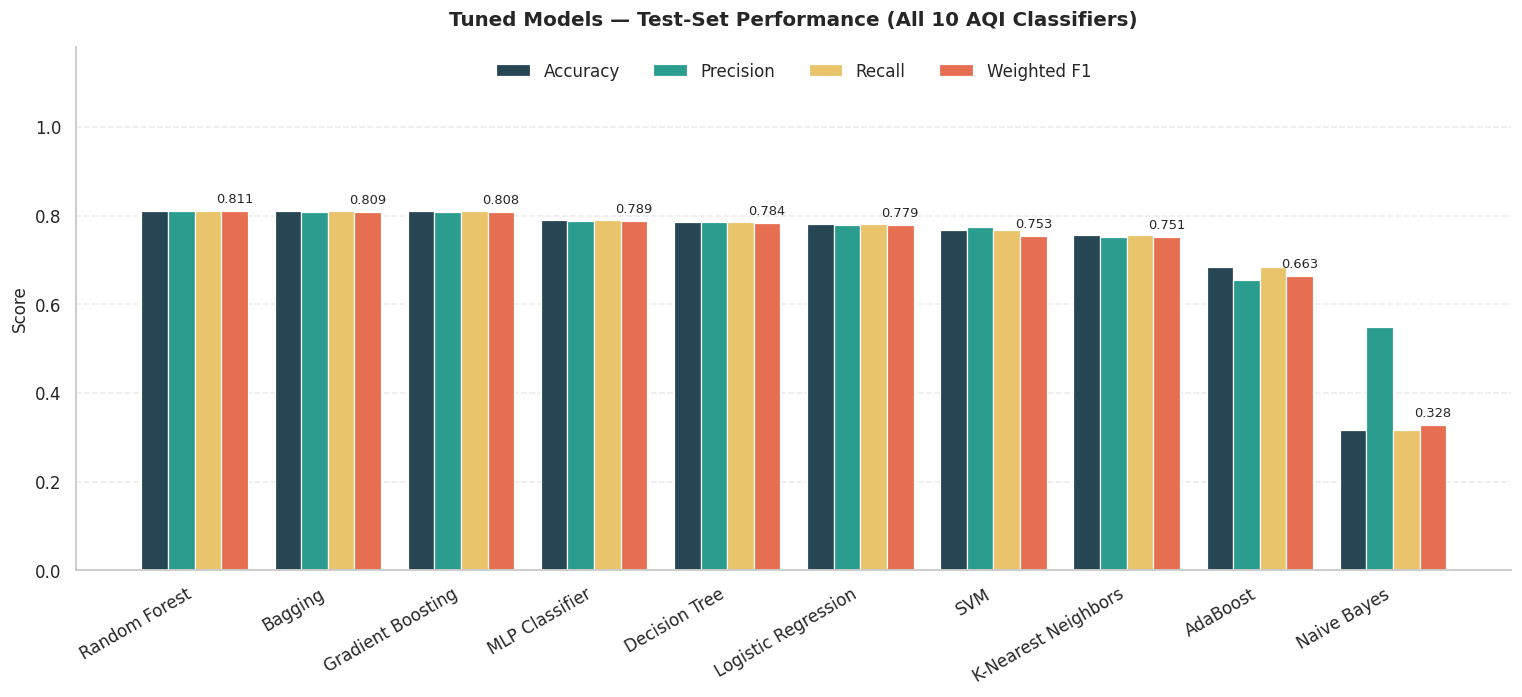

In [112]:
# Tuned models only — test-set performance, sorted by weighted F1
tuned_plot_df = tuned_results_df.sort_values("Weighted F1", ascending=False).reset_index(drop=True)
display(tuned_plot_df.round(4))

plot_metric_bars(tuned_plot_df, "Algorithm", "Tuned Models — Test-Set Performance (All 10 AQI Classifiers)")

> **Observation:** After tuning, **Random Forest moves into first place (weighted F1 0.8109)**, ahead of Bagging (0.8090) and Gradient Boosting (0.8080); all three stay within 0.003 of each other. The remaining order is MLP (0.7886), Decision Tree (0.7839), Logistic Regression (0.7797), SVM (0.7533) and KNN (0.7514) — SVM now edges past KNN — then AdaBoost (0.6631) and Naive Bayes (0.3280). The chart looks almost the same as the baseline chart, which is consistent with the small tuning gains found above.

## D8. Confusion Matrices — All 10 Tuned Models

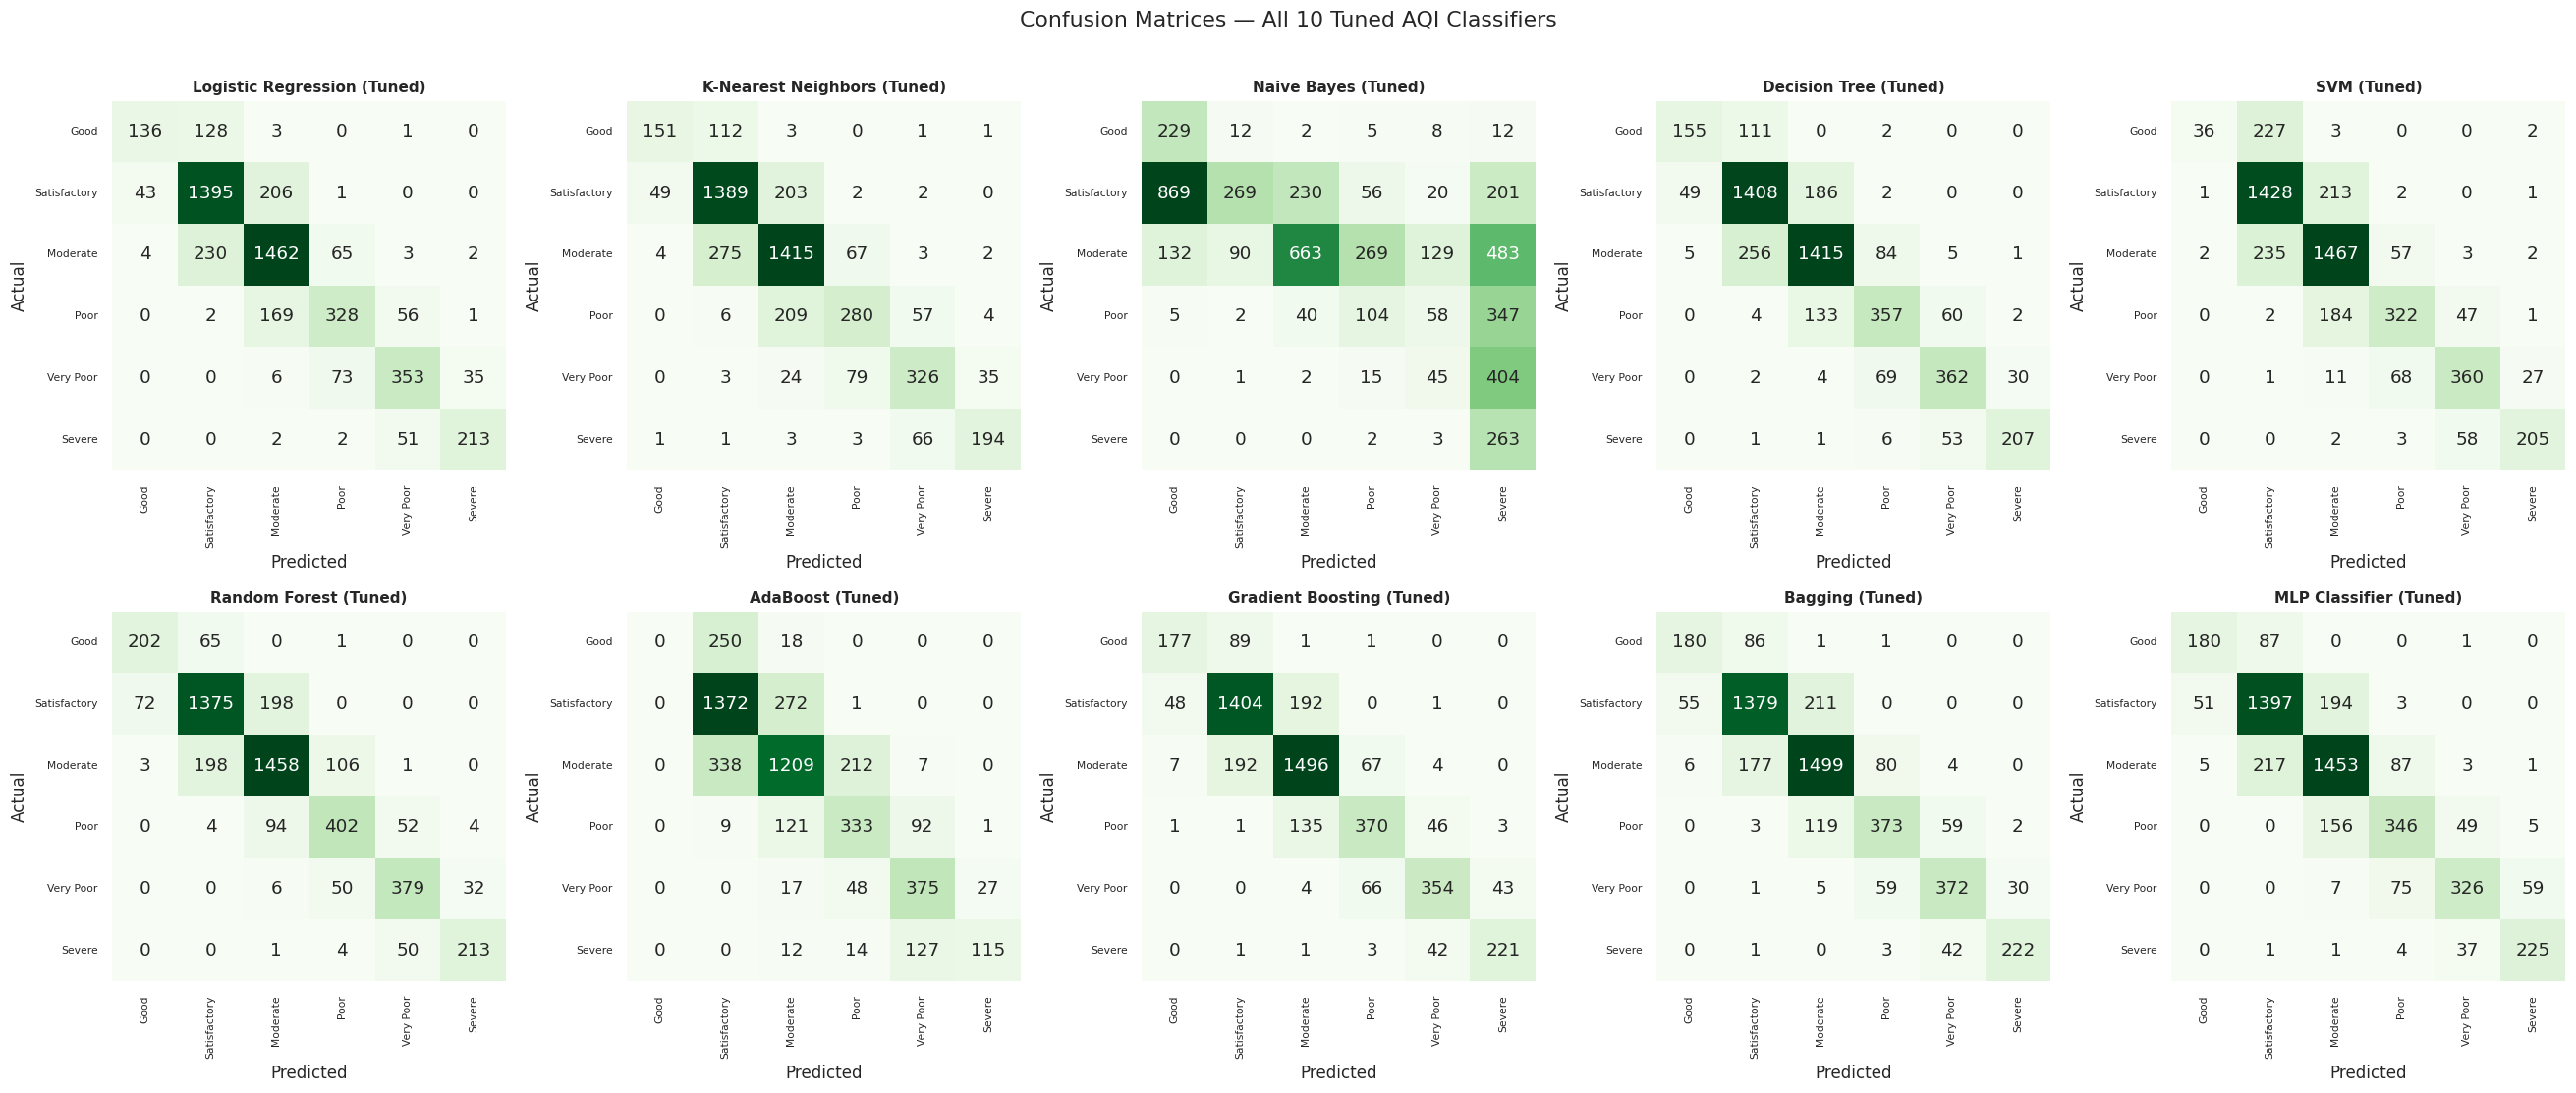

In [113]:
fig, axes = plt.subplots(2, 5, figsize=(24, 10))
labels = label_order

for ax, name in zip(axes.flat, all_model_names):
    cm = confusion_matrix(y_test, tuned_predictions[name], labels=labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Greens", cbar=False,
        xticklabels=labels, yticklabels=labels, ax=ax
    )
    ax.set_title(f"{name} (Tuned)", fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)

plt.suptitle("Confusion Matrices — All 10 Tuned AQI Classifiers", y=1.01)
plt.tight_layout()
plt.show()

> **Observation:** The pattern is the same as for the baselines — errors are between neighbouring categories. Visible changes after tuning: the tuned **Random Forest recovers more of the rare/harder classes** (Good 174 → 202, Poor 354 → 402) at a small cost to the two big classes (Satisfactory 1,405 → 1,375, Moderate 1,503 → 1,458); the tuned SVM finds more Good days (12 → 36); and Naive Bayes now gets Moderate right far more often (320 → 663) but still labels 869 Satisfactory days as Good. The panels for Decision Tree, Gradient Boosting, Bagging and MLP are identical to their baselines.

## D9. Final Model Selection

Best model by cross-validation weighted F1: Random Forest
Best CV weighted F1: 0.8011
Held-out test weighted F1: 0.8109
Classification report for the selected model:
              precision    recall  f1-score   support

        Good       0.73      0.75      0.74       268
Satisfactory       0.84      0.84      0.84      1645
    Moderate       0.83      0.83      0.83      1766
        Poor       0.71      0.72      0.72       556
   Very Poor       0.79      0.81      0.80       467
      Severe       0.86      0.79      0.82       268

    accuracy                           0.81      4970
   macro avg       0.79      0.79      0.79      4970
weighted avg       0.81      0.81      0.81      4970



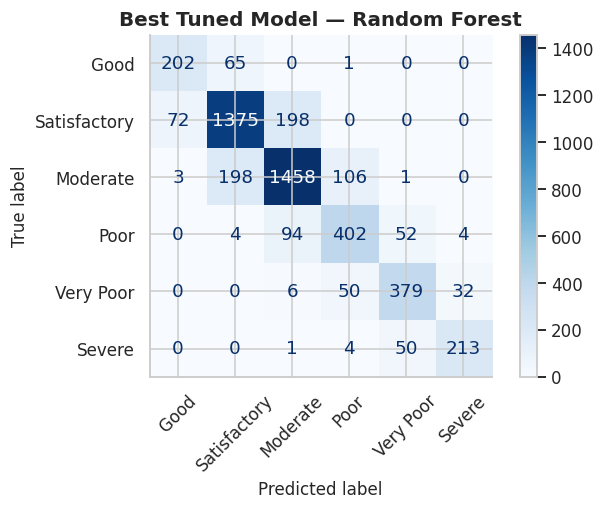

In [114]:
# Identify the best tuned model using cross-validation weighted F1
best_model_name = tuning_results_df.iloc[0]["Algorithm"]
best_model = tuned_models[best_model_name]
best_predictions = tuned_predictions[best_model_name]

print("Best model by cross-validation weighted F1:", best_model_name)
print("Best CV weighted F1:", round(tuning_results_df.iloc[0]["Best CV Weighted F1"], 4))
print("Held-out test weighted F1:", round(
    f1_score(y_test, best_predictions, average="weighted", zero_division=0), 4
))
print("Classification report for the selected model:")
print(classification_report(y_test, best_predictions, labels=label_order, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, labels=label_order,
    display_labels=label_order, xticks_rotation=45,
    cmap="Blues", values_format="d"
)
plt.title(f"Best Tuned Model — {best_model_name}")
plt.tight_layout()
plt.show()

> **Observation:** **Random Forest (tuned)** is selected on cross-validated weighted F1 (0.8011) and achieves a test weighted F1 of **0.8109** (accuracy 0.81). Per-class F1 is highest for Satisfactory (0.84) and Moderate (0.83) — the two largest classes — and lowest for **Poor (0.72) and Good (0.74)**. Macro-average F1 (0.79) is below the weighted average (0.81), confirming that smaller classes are predicted slightly worse. Severe has high precision (0.86) but lower recall (0.79): 50 of its 268 test days are predicted as Very Poor.

# H. Conclusion

The classification task predicts the `AQI_Bucket` category from city, date-derived, pollutant and engineered features. Ten classifiers were trained on a stratified 80/20 split with leakage-safe preprocessing, tuned with 3-fold GridSearchCV and evaluated on a held-out test set of 4,970 records.

**Headline results**

| | Model | Weighted F1 | Accuracy | ROC-AUC |
|---|---|---|---|---|
| Best baseline (by weighted F1) | Bagging | 0.8090 | 0.8099 | 0.9567 |
| Same model after tuning | Bagging | 0.8090 | 0.8099 | 0.9567 |
| Best tuned / selected model | Random Forest | 0.8109 | 0.8107 | 0.9604 |

**Main findings.**
- The best baseline model by weighted F1 was **Bagging (0.8090)**, with Random Forest (0.8085) and Gradient Boosting (0.8080) essentially tied. Tuning left Bagging unchanged (its baseline setting was already the best in the grid), while **Random Forest, the best model in cross-validation (0.8011), rose from 0.8085 to 0.8109** and was selected as the final model.
- **Confusions are almost entirely between neighbouring AQI categories**, mainly Satisfactory ↔ Moderate (≈200 records each way), Moderate → Poor (106), Good ↔ Satisfactory (≈65–72) and Severe → Very Poor (50). Good and Poor are the hardest classes (F1 0.74 and 0.72).
- **PM2.5, CO and PM10 carry most of the predictive signal** (≈78% of the single-tree importance), consistent with the EDA, where they correlate most strongly with AQI.
- Tree ensembles (Bagging, Random Forest, Gradient Boosting) outperform simpler models by ≈0.02–0.03 weighted F1, while **Naive Bayes fails** (F1 0.19 → 0.33 after tuning) because its independence and Gaussian assumptions do not hold for skewed, correlated pollutant data. Hyperparameter tuning changed the strong models by less than 0.003 F1 — within test-set noise — so model choice mattered much more than tuning.

**Limitations.**
- Heavy missingness (Xylene 61%, PM10 38%, NH3 35%) is handled by median imputation, and the engineered features `PM_combined` and `VOC_total` are missing whenever any component is missing.
- The classes are imbalanced (Good and Severe ≈ 5% each), which limits recall for those categories.
- The split is random, so neighbouring days of the same city appear in both training and test sets; this may make the results more optimistic than true forecasting of future air quality, which would need a time-based split.
- Several best hyperparameters sit at the edge of their grids, so the search space was probably too narrow for those models, and differences of ≈0.01 or less between models are within sampling error.
